# D41. Voice Agent 평가 자동화: 가상의 환자가 전화하고, 기계가 채점하고, 고칠 때마다 다시 시험하기

**음성 AI 전문가 과정 | 9주차 M9 평가 · 배포 · 운영 · 엣지 | 4시간**

## 학습 목표
1. 음성 비서의 평가를 **부품 · 턴 · 대화** 세 단계로 나누고, 단계마다 무엇을 재는지 설명한다.
2. STT의 **WER · CER**과 **슬롯 정확도**를 재고, 턴 단위로 **도구 호출 정확도**를 잰다.
3. 성격과 목표가 다른 **가상의 환자(사용자 시뮬레이터)** 로 통화를 자동으로 만들고, **과제 성공률**과 **규칙 준수**(루브릭)를 채점한다.
4. 목소리 · 잡음을 넣은 **스트레스 시험**, 고칠 때마다 돌리는 **회귀 시험(pytest)**, 결과를 한 장에 모은 **대시보드**를 만든다.

## 오늘의 실습 흐름
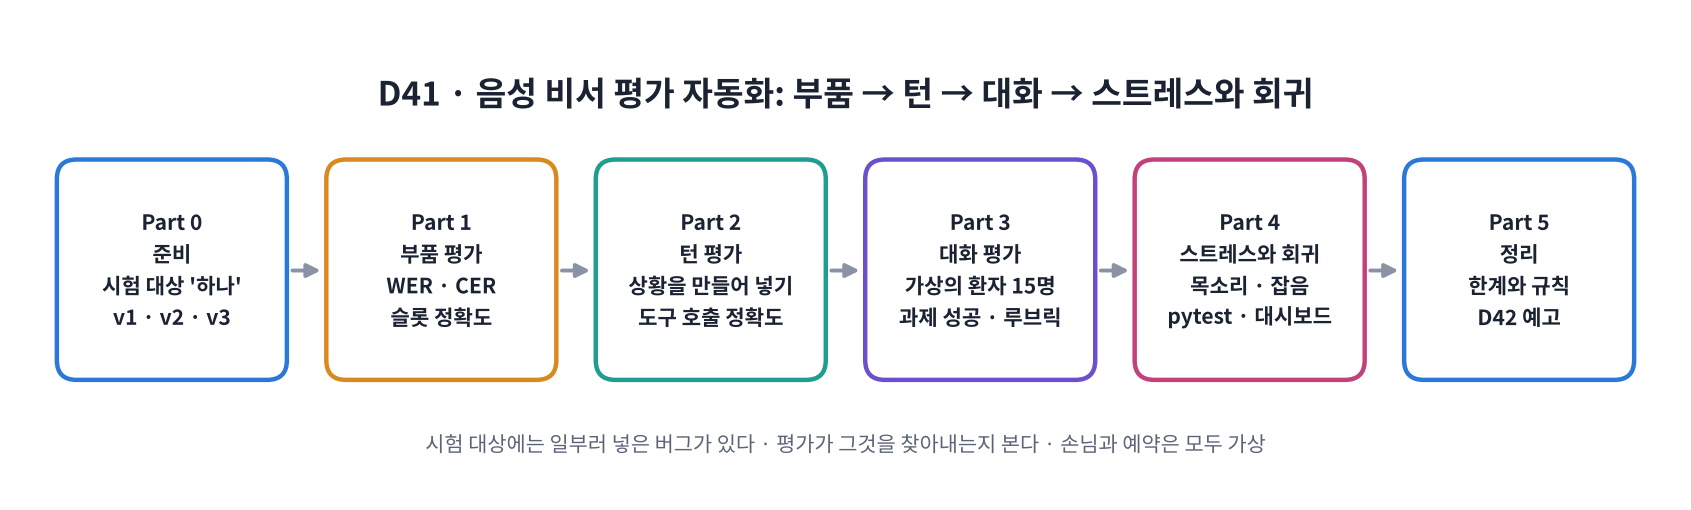

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | 왜 자동 평가인가, 세 단계, 부품 평가(WER · CER · 슬롯 정확도) | Part 0 ~ 1 · ✍️ 직접 작성 1 (WER) | 부품 평가표 |
| 2교시 | 턴 평가: 턴 시험 사례, 도구 호출 정확도 | Part 2 · ✍️ 직접 작성 2 (도구 호출 맞추기) | 버전별 턴 시험표 |
| 3교시 | 대화 평가: 가상의 환자, 과제 성공률, 루브릭 채점, LLM 심사 | Part 3 · ✍️ 직접 작성 3 (과제 성공) | 시나리오 15개 × 버전 3개의 결과 |
| 4교시 | 음성 · 잡음 스트레스 시험, 지연, 회귀 시험(pytest), 대시보드 | Part 4 ~ 5 · ✍️ 직접 작성 4 (회귀 찾기) · 워크시트 25문항 | **평가 하네스 + 결과 대시보드(HTML)** |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day41/animation.html) | 평가의 세 단계(D41-2) · WER과 뜻(D41-3) · 도구 호출 맞추기(D41-4) · 가상의 환자(D41-5) · 루브릭 채점(D41-6) · 잡음 스트레스(D41-7) · 회귀 시험(D41-8). 탭마다 **▶ 시연 보기**를 누르면 자막과 함께 스스로 움직입니다 |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day41/worksheet.html) | 수업을 모두 마친 뒤 하루 한 장 25문항 (객관식 · OX · 모두 고르기 · 선 잇기 · 순서 · 코드 직접 쓰기 · 계산 · 분류 · 직접 조작), 오답 정리 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. **키가 없어도 끝까지 실행됩니다.** Gemini 또는 OpenAI 키가 있으면 Colab 왼쪽 🔑 **보안 비밀**에 `GEMINI_API_KEY` 또는 `OPENAI_API_KEY`로 넣어 두세요(D22와 같음). 그러면 3교시의 **LLM 심사 · LLM 손님**이 함께 실행됩니다. 키는 **출력하지 않습니다.**
- ⭐ **핵심 코드** 셀은 완성된 코드입니다. 실행한 뒤 `# ⭐` 표시가 붙은 줄을 읽어 보세요. 🔍 **핵심 줄 해설 보기**를 누르면 설명이 펼쳐집니다.
- ✍️ **직접 작성** 셀은 교시마다 하나씩, 모두 네 개입니다. `...` 자리에 코드를 직접 쓰고 실행하면 ✅ 또는 ❌가 나옵니다. 막히면 💡 **힌트 보기**, 다 쓴 뒤에는 🔑 **정답 보기**를 누르세요. 작성하지 않아도 아래 셀은 그대로 실행됩니다.
- ✏️ 표시 줄은 값을 **직접 바꿔** 다시 실행해 보는 줄입니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 규칙 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 토론 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU** 권장(4교시의 음성 시험이 빨라집니다). 오늘의 환자 · 이름 · 전화번호 · 예약은 모두 **가상**입니다.
>
> 🧪 **오늘의 약속**: 시험 대상인 비서 '하나'에는 **일부러 넣은 버그**가 있습니다(v1 · v2). 버그를 미리 찾아 고치지 말고, **평가가 그것을 찾아내는지**를 봅니다.

> 🎬 **애니메이션 D41-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#flow) — 가상의 환자가 전화를 걸고, 채점표가 채워지고, 버전이 바뀔 때마다 다시 시험하는 고리

## Part 0. 준비

> 🛠️ Whisper · Edge TTS는 평소와 같습니다. 회귀 시험에 쓰는 `pytest`를 확인합니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile uroman edge-tts openai pytest
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, time, html, random, warnings, logging, tempfile, functools, subprocess
import numpy as np
import pandas as pd
import librosa
import torch
import requests
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display, Markdown, HTML
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000                                               # 말소리 분석용 (Whisper · 감정 · AST)
print(" · ".join(f"{p} {md.version(p)}" for p in ["transformers", "librosa", "torch"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능, 조금 느림)")

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if any(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    try:
        ok = bool(np.allclose(np.asarray(got, float), np.asarray(want, float), atol=tol))
    except (TypeError, ValueError):
        ok = list(items) == list(want if isinstance(want, (list, tuple)) else [want])
    show = lambda v: str([round(float(x), 4) if isinstance(x, (int, float, np.floating)) else x for x in (v if isinstance(v, (list, tuple)) else [v])])[:110]
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {show(got)} · 기대 {show(want)} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

def edit_distance(r, h):                                 # 두 열(글자들 또는 낱말들) 사이의 편집 거리 (D10)
    d = list(range(len(h) + 1))
    for i, a in enumerate(r, 1):
        prev, d[0] = d[0], i
        for j, b in enumerate(h, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (a != b))
    return d[-1]

def cer(ref, hyp):                                       # 글자 오류율: 공백 · 문장 부호를 빼고 편집 거리 ÷ 정답 글자 수
    r, h = [re.sub(r"[^0-9A-Za-z가-힣]", "", s) for s in (ref, hyp)]
    return edit_distance(r, h) / max(1, len(r))

In [ ]:
# 🔊 모델 준비 (평소와 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS)
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

print("받아쓰기 확인:", stt(tts("한빛치과입니다. 무엇을 도와드릴까요?")))

In [ ]:
# 🔑 (선택) LLM 연결: 키가 있으면 3교시의 LLM 심사 · LLM 손님을 실행, 없으면 그 부분만 건너뜀
def secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name) or None

MODELS = {"gemini": "gemini-3.5-flash-lite", "openai": "gpt-5-mini"}     # ✏️ 모델 이름은 수업 당일 각 회사 문서에서 확인
KEYS = {"gemini": "GEMINI_API_KEY", "openai": "OPENAI_API_KEY"}
BASE_URLS = {"gemini": "https://generativelanguage.googleapis.com/v1beta/openai/", "openai": None}   # Gemini도 'OpenAI 호환' 주소를 제공
BACKEND = next((p for p in ["gemini", "openai"] if secret(KEYS[p])), "none")
if BACKEND != "none":
    from openai import OpenAI
    client = OpenAI(api_key=secret(KEYS[BACKEND]), base_url=BASE_URLS[BACKEND])

def llm(system, user, max_tokens=300):                   # 글자 → 글자. 키가 없거나 실패하면 None
    if BACKEND == "none": return None
    try:
        r = client.chat.completions.create(model=MODELS[BACKEND], max_tokens=max_tokens, messages=[{"role": "system", "content": system}, {"role": "user", "content": user}])
        return (r.choices[0].message.content or "").strip()
    except Exception as e:
        print(f"⚠️ LLM 호출 실패 ({type(e).__name__}: {str(e)[:100]})"); return None

print("LLM:", BACKEND, MODELS.get(BACKEND, ""), "(키 값은 출력하지 않음)" if BACKEND != "none" else "→ 키가 없어 LLM 심사 · LLM 손님은 건너뜁니다. 나머지는 모두 실행됩니다.")

### 시험 대상: 예약 비서 '하나'의 머리

D34에서 만든 슬롯 채우기 비서를 **글자 → 글자** 함수로 줄인 것입니다. 진료 · 날짜 · 시간 · 성함 · 전화번호를 모으고, **확인을 받은 뒤** 빈자리를 확인(`check_slot`)하고 예약(`book`)합니다. 버전이 셋입니다.

| 버전 | 설명 |
|---|---|
| **v1** | 처음 만든 것. 버그가 여럿 숨어 있음 |
| **v2** | v1의 버그를 고친 것. 그런데 고치다가 **새 버그**가 하나 들어감 |
| **v3** | v2의 새 버그까지 고친 것 |

> 코드를 다 읽을 필요는 없습니다. `🐞` 표시가 버그가 있는 줄입니다. 지금은 눈으로만 훑고, **평가가 이것들을 찾아내는지** 봅니다.

In [ ]:
# 🦷 시험 대상: 한빛치과 예약 비서 '하나' (글자로 듣고 글자로 답하는 부분 · 버전 v1 → v2 → v3)
TREAT = {"스케일링": "스케일링", "충치": "충치 치료", "사랑니": "사랑니 발치", "임플란트": "임플란트 상담", "검진": "정기 검진"}
NUM = {"한": 1, "두": 2, "세": 3, "네": 4, "다섯": 5, "여섯": 6, "일곱": 7, "여덟": 8, "아홉": 9, "열": 10, "열한": 11, "열두": 12}
MIN = {"십": 10, "이십": 20, "삼십": 30, "사십": 40, "오십": 50}
ORDER = ["treatment", "date", "time", "name", "phone"]
ASK = {"treatment": "어떤 진료를 예약해 드릴까요?", "date": "원하시는 날짜를 말씀해 주세요.", "time": "몇 시가 좋으실까요?", "name": "예약하실 분의 성함을 말씀해 주세요.", "phone": "연락받으실 전화번호를 말씀해 주세요."}

def ko_time(hhmm):                                       # "15:30" → "오후 3시 30분"
    h, m = map(int, hhmm.split(":")); ap = "오전" if h < 12 else "오후"; h12 = h if h <= 12 else h - 12
    return f"{ap} {h12}시" + (f" {m}분" if m else "")

def parse(text, version="v3", awaiting=None):            # 말에서 예약 정보(슬롯) 뽑기 → {슬롯: 값}
    out = {}
    for k, v in TREAT.items():
        if k in text: out["treatment"] = v
    m = re.search(r"(오늘|내일|모레)|(이번|다음) ?주 ?([월화수목금토일])요일", text)
    if m: out["date"] = m.group(1) or f"{m.group(2)} 주 {m.group(3)}요일"
    for m in re.finditer(r"(오전|오후|아침|저녁)? ?(\d{1,2}|열한|열두|다섯|여섯|일곱|여덟|아홉|한|두|세|네|열) ?시 ?(반|(\d{1,2}|[이삼사오]?십) ?분)?", text):
        h = int(m.group(2)) if m.group(2).isdigit() else NUM[m.group(2)]
        mi = 30 if m.group(3) == "반" else (int(m.group(4)) if m.group(4) and m.group(4).isdigit() else MIN.get(m.group(4), 0))
        pm = m.group(1) in ("오후", "저녁")
        if version == "v2": h += 12 if pm else 0                                   # 🐞 v2: '오후'면 무조건 12를 더함 → 오후 12시가 24시
        elif (pm and h < 12) or (m.group(1) is None and h <= 6): h += 12           # 오후 3시 → 15시 · 그냥 '3시'도 병원 시간으로 15시
        if "time" not in out or version != "v1": out["time"] = f"{h:02d}:{mi:02d}"  # 한 문장에 시각이 둘이면 뒤의 것 (v1은 앞의 것)
    m = re.search(r"(?:이름은|성함은|저는)\s*([가-힣]{2,4}?)(?:이라고|라고|입니다|이에요|예요|이고|인데요)", text) or (
        re.fullmatch(r"\s*([가-힣]{2,4}?)(?:이라고 합니다|라고 합니다|입니다|이에요|예요|이요|요)?[.!\s]*", text) if awaiting == "name" else None)
    if m and m.group(1) not in ("네", "예", "아니"): out["name"] = m.group(1)
    digits = re.sub(r"[^0-9]", "", re.sub(r"\d{1,2} ?시|\d{1,2} ?분", "", text))
    if version != "v1":                                                            # 🐞 v1: 한글로 읽은 번호(공일공 …)를 못 알아들음
        m2 = re.search(r"[공영][일][공영일육칠팔구][ -]?[공영일이삼사오육칠팔구]{3,4}[ -]?[공영일이삼사오육칠팔구]{4}", text)
        if m2: digits = "".join(str("공일이삼사오육칠팔구".index(c)) for c in m2.group().replace("영", "공") if c in "공일이삼사오육칠팔구")
    if re.fullmatch(r"01\d{8,9}", digits): out["phone"] = digits
    return out

class Hana:
    def __init__(self, version="v3", db=None):
        self.v, self.db = version, db if db is not None else {"bookings": [], "busy": {("모레", "15:00")}, "others": {"김철수": "내일 오후 2시"}}
        self.slots, self.stage, self.asked, self.fails, self.closed, self.calls = {}, "collect", None, 0, 0, []
    def tool(self, tool_name, **args):                   # 도구 호출: 기록해 두고 실행
        self.calls.append({"name": tool_name, "args": args})
        if tool_name == "check_slot": return 9 <= int(args["time"][:2]) < 18, (args["date"], args["time"]) not in self.db["busy"]
        if tool_name == "book": self.db["bookings"].append(dict(args))
    def confirm_text(self):
        s = self.slots; return f'{s["date"]} {ko_time(s["time"])}에 {s["treatment"]}, {s["name"]} 님, 연락처 {s["phone"]}(으)로 예약할까요? 맞으시면 "네"라고 말씀해 주세요.'
    def finish(self):                                    # 빈자리 확인 → 예약
        s = self.slots; open_, free = self.tool("check_slot", date=s["date"], time=s["time"])
        if not open_ or not free:
            self.closed += not open_
            if self.closed >= 2: self.tool("handoff", reason="진료 시간 밖의 시각이 되풀이됨"); self.stage = "done"; return "죄송합니다. 상담원에게 연결해 드리겠습니다."
            del self.slots["time"]; self.stage, self.asked = "collect", "time"
            return ("그 시간은 진료 시간이 아닙니다. " if not open_ else "죄송합니다. 그 시간은 예약이 차 있습니다. ") + "다른 시간을 말씀해 주세요."
        self.tool("book", **s); self.stage = "done"
        return f'{s["name"]} 님, {s["date"]} {ko_time(s["time"])} {s["treatment"]} 예약되었습니다. 감사합니다.'
    def reply(self, text):                               # 사용자 말 한 마디 → 비서의 답 한 마디
        if self.stage == "done": return "예약이 끝났습니다. 감사합니다."
        pre = ""
        if re.search(r"무슨 병|진단|약.{0,6}(먹|추천)|왜 아픈", text):
            pre = "진통제를 드시고 찬 음식을 피하세요. " if self.v == "v1" else "진단이나 약 추천은 드릴 수 없습니다. 진료 예약을 도와드릴게요. "   # 🐞 v1: 의료 조언
        m = re.search(r"([가-힣]{2,4}) ?씨.{0,8}예약.{0,6}(언제|알려)", text)
        if m: pre += (f'{m.group(1)} 님은 {self.db["others"].get(m.group(1), "예약이 없")}에 예약입니다. ' if self.v == "v1" else "다른 분의 예약 정보는 알려 드릴 수 없습니다. ")   # 🐞 v1: 남의 정보
        got = parse(text, self.v, self.asked)
        for k, val in got.items():
            if k not in self.slots or self.v != "v1": self.slots[k] = val          # 🐞 v1: 이미 들은 정보는 고쳐 말해도 안 바꿈
        if self.stage == "confirm":
            if not got and re.search(r"^(네|예|응)\b|맞아요|맞습니다|그래요|좋아요", text.strip()) and not re.search(r"아니|바꿔|말고", text): return pre + self.finish()
            return pre + (self.confirm_text() if got else "어느 부분을 바꿔 드릴까요? 날짜 · 시간 · 진료 · 성함 · 전화번호 가운데 말씀해 주세요.")
        missing = [k for k in ORDER if k not in self.slots]
        if not missing:
            if self.v == "v1": return pre + self.finish()                          # 🐞 v1: 확인 없이 바로 예약
            self.stage = "confirm"; return pre + self.confirm_text()
        self.fails = self.fails + 1 if (missing[0] == self.asked and not got and not pre) else 0
        if self.fails >= 3:
            self.tool("handoff", reason=f"{missing[0]} 알아듣지 못함"); self.stage = "done"; return "죄송합니다. 상담원에게 연결해 드리겠습니다."
        self.asked = missing[0]; return pre + ("죄송합니다. 다시 한번 " if self.fails else "") + ASK[missing[0]]

a = Hana("v3")
for u in ["안녕하세요, 스케일링 예약하고 싶습니다.", "내일 오전 10시요.", "김민준입니다.", "010-1234-5678입니다.", "네, 맞아요."]:
    print("🧑", u); print("🤖", a.reply(u))
print("도구 호출:", a.calls)

## Part 1. 왜 자동 평가인가 · 부품 평가  ·  1교시

지금까지는 비서를 고칠 때마다 **직접 말을 걸어 보고** "잘 되네" 하고 넘어갔습니다. 손님이 다섯 종류, 예약 내용이 세 가지, 잡음 조건이 네 가지면 60가지입니다. 고칠 때마다 60통을 손으로 걸 수는 없습니다. 그리고 손으로 걸면 **늘 되는 말만** 하게 됩니다.

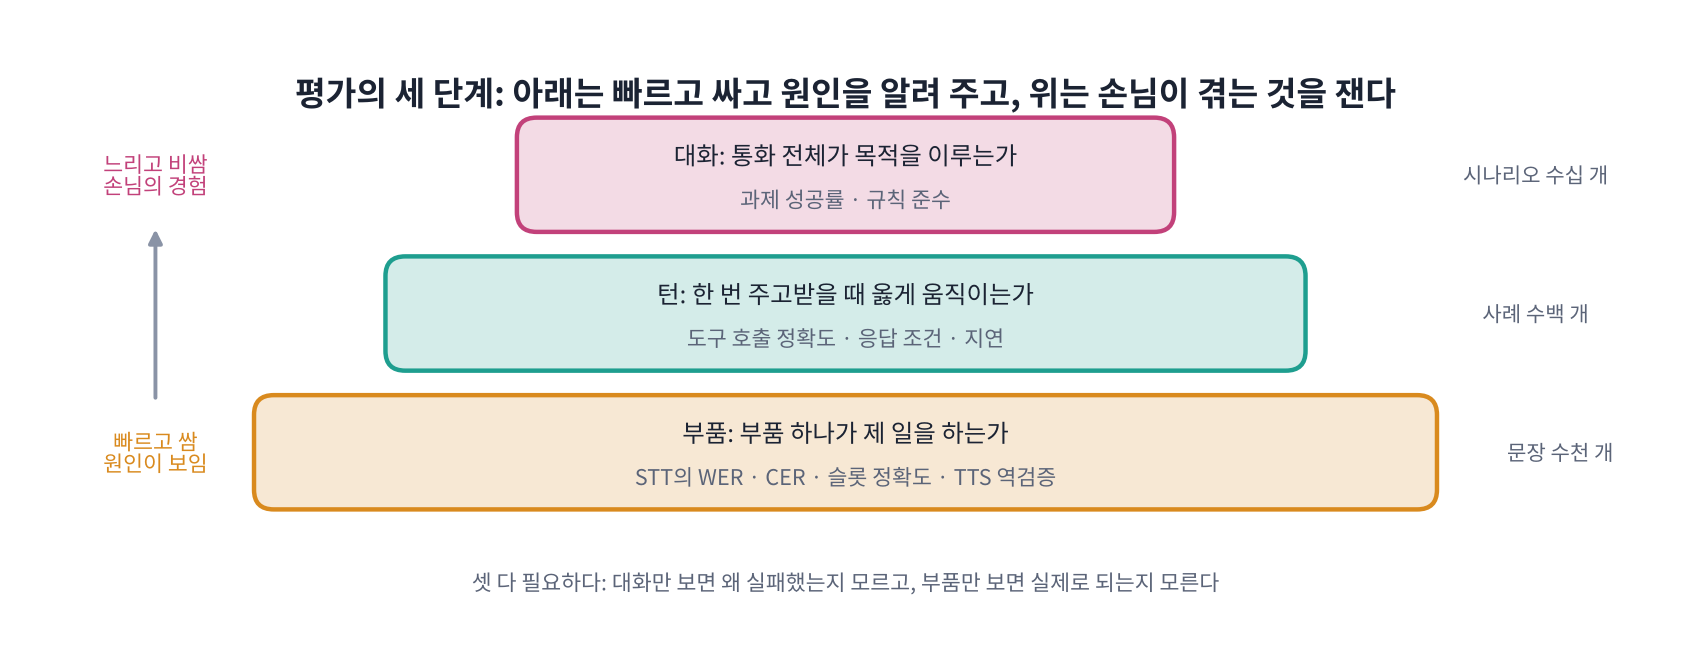

| 단계 | 무엇을 재나 | 예 | 빠르기 · 값 |
|---|---|---|---|
| **부품** | 부품 하나가 제 일을 하는가 | STT의 WER · CER, TTS의 역검증 CER | 가장 빠르고 쌈. 어디가 문제인지 바로 앎 |
| **턴** | 한 번 주고받을 때 옳게 움직이는가 | 도구 호출 정확도, 응답 조건, 지연 | 빠름. 상황을 직접 만들어 넣음 |
| **대화** | 통화 전체가 목적을 이루는가 | 과제 성공률, 규칙 준수 | 느리고 비쌈. 하지만 손님이 겪는 것은 이것 |

> 💬 **쉽게 말하면**: 자동차를 검사할 때 **부품 검사**(브레이크 패드의 두께), **동작 검사**(브레이크를 밟으면 서는가), **주행 시험**(시내를 한 바퀴 돌고 무사히 돌아오는가)을 다 합니다. 주행 시험만 하면 왜 실패했는지 모르고, 부품 검사만 하면 실제로 달릴 수 있는지 모릅니다.

> 🍎 **비유**: 식당의 위생 점검표입니다. 손님이 없을 때도, 주방장이 바뀌어도, 메뉴를 고쳐도 **같은 표로 다시** 점검합니다. 표가 있어야 "지난달보다 나아졌는가"를 말할 수 있습니다.

> 🎬 **애니메이션 D41-2:** [평가의 세 단계](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#pyramid) — 같은 실패가 세 단계에서 각각 어떻게 보이는지

### 1-1. 부품 평가: 받아쓰기는 얼마나 틀리나

📐 **핵심 식 하나**: `WER = 낱말 단위의 편집 거리 ÷ 정답의 낱말 수` (CER은 글자 단위)

한국어는 띄어쓰기에 따라 낱말이 달라져서 WER이 흔들립니다. 그래서 CER을 함께 봅니다(D10). 그런데 비서에게 정말 중요한 것은 글자가 아니라 **예약 정보(슬롯)** 입니다. `오후 세 시`를 `오후 3시`로 받아쓰면 글자는 틀렸지만 뜻은 같고, `네 시`로 받아쓰면 한 글자만 틀렸지만 **예약이 틀립니다.**

> 🎬 **애니메이션 D41-3:** [WER과 뜻](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#wer) — 받아쓴 글을 바꿔 가며 WER · CER · 슬롯이 따로 움직이는 것 보기 (값은 화면에서 실제로 계산)

In [ ]:
# ✍️ 직접 작성 1 (1교시): 낱말 오류율 WER
# ref(정답)와 hyp(받아쓴 글)를 공백으로 나눠 낱말의 리스트로 만들고,
# edit_distance(정답 낱말들, 받아쓴 낱말들) ÷ 정답 낱말 수를 돌려주세요. 정답이 빈 문자열이면 0.0을 돌려줍니다. (2 ~ 3줄)
def wer(ref, hyp):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W1_OK = practice(lambda: [wer("내일 오후 세 시요", "내일 오후 세 시요"), wer("내일 오후 세 시요", "내일 오후 네 시요"), wer("내일 오후 세 시요", "내일 오후 3시요"),
                          wer("스케일링 예약", "스케일링 예약 하고 싶어요"), wer("네 맞아요", ""), wer("", "네")], [0.0, 0.25, 0.5, 1.0, 1.0, 0.0])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 낱말로 나누기: `r, h = ref.split(), hyp.split()`.
2. 정답이 비어 있으면 나눌 수 없습니다: `if not r: return 0.0`.
3. `return edit_distance(r, h) / len(r)`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def wer(ref, hyp):
    r, h = ref.split(), hyp.split()
    if not r:
        return 0.0
    return edit_distance(r, h) / len(r)
```

**해설**: `edit_distance`는 글자의 열에도 낱말의 열에도 똑같이 쓸 수 있습니다. 리스트를 넣으면 **낱말 단위**로 셉니다. 시험 사례를 보세요. ① 같으면 0 ② `세` → `네` 한 낱말이 바뀌어 1/4 = 0.25 ③ `세 시요` → `3시요`는 두 낱말이 한 낱말로 바뀌어(바꾸기 1 + 지우기 1) 2/4 = 0.5. **뜻은 같은데 ②보다 두 배 나쁩니다.** ④ 정답 2낱말 뒤에 2낱말(`하고` · `싶어요`)이 더 붙어 2/2 = 1.0. 더 많이 붙으면 WER은 **1을 넘을 수도** 있습니다. ⑤ 아무것도 못 받아쓰면 정답의 낱말을 모두 지운 것이라 1.0. 나누는 수는 **정답**의 낱말 수입니다. 받아쓴 글의 낱말 수로 나누면 ④ · ⑤가 틀립니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 부품 평가 — 받아쓰기의 WER · CER · 슬롯 정확도 (깨끗할 때와 시끄러울 때) + TTS 역검증
USER_SAYS = ["내일 오전 10시에 스케일링 예약하고 싶습니다.", "다음 주 수요일 오후 12시요.", "모레 오후 3시쯤이면 좋겠는데요.", "그럼 오후 4시 30분으로 해 주세요.",
             "제 이름은 김민준입니다.", "010-1234-5678입니다.", "공일공 이삼사오 육칠팔구입니다.", "아 참, 시간은 오전 11시로 바꿔 주세요.", "사랑니 발치 받으려고 하는데요.", "네, 맞아요."]   # 손님이 할 법한 말
AGENT_SAYS = [ASK[k] for k in ORDER] + ['내일 오전 10시에 스케일링, 김민준 님으로 예약할까요? 맞으시면 "네"라고 말씀해 주세요.']

def add_noise(y, snr, seed=0):                           # 잡음을 정한 SNR로 섞기 (D39)
    n = np.convolve(np.random.default_rng(seed).standard_normal(len(y)), np.ones(8) / 8, mode="same").astype(np.float32)
    return (y + n * np.sqrt(np.mean(y ** 2) / (np.mean(n ** 2) * 10 ** (snr / 10)))).astype(np.float32)

def slot_acc(ref, hyp):                                  # 정답에서 뽑힌 예약 정보가 받아쓴 글에서도 똑같이 뽑히는가 (정보가 없는 문장은 None)
    want, got = parse(ref), parse(hyp)                                             # ⭐ 비서의 눈으로 본 뜻
    return None if not want else float(all(got.get(k) == v for k, v in want.items()))

_wer = wer if globals().get("W1_OK") else (lambda r, h: edit_distance(r.split(), h.split()) / max(1, len(r.split())))
rows, HEARD = [], {}
for name, snr in [("깨끗함", None), ("잡음 SNR 10 dB", 10), ("잡음 SNR 0 dB", 0)]:      # ✏️ 조건을 더해 보세요
    hyps = [stt(user_tts(t) if snr is None else add_noise(user_tts(t), snr, k)) for k, t in enumerate(USER_SAYS)]; HEARD[name] = hyps
    sa = [s for s in (slot_acc(r, h) for r, h in zip(USER_SAYS, hyps)) if s is not None]
    rows.append({"부품": "STT", "조건": name, "WER": np.mean([_wer(r, h) for r, h in zip(USER_SAYS, hyps)]), "CER": np.mean([cer(r, h) for r, h in zip(USER_SAYS, hyps)]), "슬롯 정확도": np.mean(sa)})   # ⭐ 세 가지를 나란히
tts_cer = np.mean([cer(t, stt(tts(t))) for t in AGENT_SAYS])                        # TTS: 비서의 말을 합성 → 받아쓰기 → 원문과 비교 (D20)
rows.append({"부품": "TTS", "조건": "역검증", "WER": np.nan, "CER": tts_cer, "슬롯 정확도": np.nan})
COMP = pd.DataFrame(rows); display(COMP.style.format({"WER": "{:.1%}", "CER": "{:.1%}", "슬롯 정확도": "{:.0%}"}, na_rep="-"))
with pd.option_context("display.max_colwidth", 46):
    display(pd.DataFrame({"손님이 한 말": USER_SAYS, "깨끗할 때 받아쓴 글": HEARD["깨끗함"], "WER": [round(_wer(r, h), 2) for r, h in zip(USER_SAYS, HEARD["깨끗함"])],
                          "슬롯": ["-" if slot_acc(r, h) is None else "⭕" if slot_acc(r, h) else "❌" for r, h in zip(USER_SAYS, HEARD["깨끗함"])]}))
play(add_noise(user_tts(USER_SAYS[0]), 0), SR, "SNR 0 dB: " + USER_SAYS[0])
verify(len(COMP) == 4 and COMP["CER"].between(0, 5).all() and COMP["슬롯 정확도"].dropna().between(0, 1).all() and slot_acc("내일 오후 세 시요", "내일 오후 3시요") == 1.0 and slot_acc("내일 오후 세 시요", "내일 오후 네 시요") == 0.0,
       "조건 네 줄의 평가표 · '세 시'를 '3시'로 받아쓰면 슬롯은 맞고, '네 시'로 받아쓰면 슬롯이 틀림")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
want, got = parse(ref), parse(hyp)
return None if not want else float(all(got.get(k) == v for k, v in want.items()))
rows.append({"부품": "STT", "조건": name, "WER": …, "CER": …, "슬롯 정확도": np.mean(sa)})
```

**해설**: **세 숫자가 다른 이야기를 합니다.** 아래 표(깨끗할 때)에서 WER이 0이 아닌데 슬롯이 ⭕인 줄을 찾아보세요. Whisper가 `10시`를 `열 시`로, `010-1234-5678`을 띄어쓰기만 다르게 적으면 WER은 오르지만 비서가 뽑는 예약 정보는 같습니다. 반대로 WER은 작은데 슬롯이 ❌인 줄이 있다면 그것이 **진짜 사고**입니다(시각이나 번호의 한 글자). `slot_acc`는 비서가 쓰는 `parse`를 정답과 받아쓴 글에 **똑같이** 적용해 비교합니다. "우리 시스템의 눈으로 봤을 때 뜻이 같은가"를 재는 것이어서, WER보다 **과제에 가까운 지표**입니다. 위 표에서 잡음이 커질 때 세 숫자가 어떻게 움직이는지 보세요. 대개 WER · CER이 먼저 오르고 슬롯 정확도는 조금 더 버티다가 무너집니다. **부품 지표의 쓸모**는 여기에 있습니다. 4교시에 통화가 실패했을 때 "STT가 못 들어서인가, 비서가 잘못 판단해서인가"를 가릴 수 있습니다. TTS의 역검증 CER은 어제(D40)와 같은 방법입니다. 이름과 전화번호는 가상의 것이고, 문장이 열 개뿐이라 숫자는 거칩니다. 실제로는 **실제 통화에서 뽑은 수백 문장**(D39의 방법으로 비식별화한 것)으로 잽니다.

</details>

**❓ 생각해 보기**
1. 깨끗할 때의 표에서 WER이 가장 높은 문장은 무엇인가요? 그 문장의 슬롯은 맞았나요? WER만 보고 "STT가 나쁘다"고 말해도 될까요?
2. `공일공 이삼사오 육칠팔구`를 Whisper는 어떻게 받아썼나요? 받아쓴 글이 `010 2345 6789`든 `공일공 …`이든 비서가 번호를 뽑을 수 있으려면 `parse`가 무엇을 해야 하나요? (D34의 ITN)
3. 부품 평가가 모두 좋은데 통화가 실패할 수 있을까요? 반대로 부품 평가가 나쁜데 통화가 성공할 수 있을까요?

> ⏸️ **1교시 끝.** 워크시트는 4교시가 끝난 뒤 한 번에 풉니다.

## Part 2. 턴 평가: 한 번 주고받을 때 옳게 움직이는가  ·  2교시

부품이 좋아도 비서가 **엉뚱한 행동**을 하면 소용없습니다. 턴 평가는 "이런 상황에서 이런 말을 들으면 이렇게 해야 한다"를 하나씩 적어 두고 검사합니다. 통화 전체를 돌리지 않고 **그 순간의 상태를 직접 만들어 넣기** 때문에 빠르고, 실패하면 어디가 틀렸는지 바로 압니다.

| 시험 사례에 적는 것 | 예 |
|---|---|
| **상황** (이미 모은 정보 · 지금 단계) | 다섯 가지를 다 모았고 확인을 기다리는 중 |
| **입력** (손님의 말) | "네, 맞아요." |
| **기대하는 도구 호출** | `check_slot(date, time)` → `book(…)` 순서로 |
| **기대하는 응답의 조건** | "예약되었습니다"가 들어 있다 / "드세요"가 **없다** |

📐 **핵심 식 하나**: `도구 호출 정확도 = 기대한 호출과 실제 호출이 맞은 사례 수 ÷ 전체 사례 수`

도구 호출이 '맞다'는 것은 ① **같은 도구를** ② **같은 순서로** ③ **기대한 인자가 같은 값으로** 불렸다는 뜻입니다. 부르지 말아야 할 때 부르지 않는 것도 맞은 것입니다.

> 💬 **쉽게 말하면**: 운전면허 기능 시험입니다. "빨간불에서 선다", "깜빡이를 켜고 차선을 바꾼다"를 하나씩 봅니다. 도로 주행(대화 평가)보다 먼저, 따로 봅니다.

> 🍎 **비유**: 요리사에게 "주문서에 '땅콩 알레르기'가 적혀 있으면 어떻게 하나요?"를 묻는 것입니다. 실제 손님이 올 때까지 기다리지 않고 **상황을 만들어** 물어봅니다.

> 🎬 **애니메이션 D41-4:** [도구 호출 맞추기](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#tools) — 기대한 호출과 실제 호출을 나란히 놓고 어디가 다른지 보기

In [ ]:
# ✍️ 직접 작성 2 (2교시): 도구 호출이 기대와 맞는가
# expected와 actual은 [{"name": 도구 이름, "args": {인자: 값}}, ...] 꼴의 리스트입니다.
# ① 개수가 같고 ② 순서대로 name이 같고 ③ expected의 args에 적힌 인자가 actual에도 같은 값으로 있으면 True.
#    (actual에 인자가 더 있는 것은 괜찮습니다.) (3 ~ 5줄)
def tool_match(expected, actual):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_c = lambda n, **a: {"name": n, "args": a}
W2_OK = practice(lambda: [tool_match([], []), tool_match([_c("book", time="15:00")], [_c("book", time="15:00", name="김민준")]), tool_match([_c("book", time="15:00")], [_c("book", time="16:00")]),
                          tool_match([_c("check_slot"), _c("book")], [_c("book"), _c("check_slot")]), tool_match([_c("check_slot")], [_c("check_slot"), _c("book")]), tool_match([], [_c("book")]),
                          tool_match([_c("book", name="김민준")], [_c("book")])], [True, True, False, False, False, False, False])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 개수부터 봅니다: `if len(expected) != len(actual): return False`.
2. `for e, a in zip(expected, actual):`에서 이름이 다르면 `return False`.
3. 인자 비교: `if any(a["args"].get(k) != v for k, v in e["args"].items()): return False`. 반복문이 끝나면 `return True`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def tool_match(expected, actual):
    if len(expected) != len(actual):
        return False
    for e, a in zip(expected, actual):
        if e["name"] != a["name"]:
            return False
        if any(a["args"].get(k) != v for k, v in e["args"].items()):
            return False
    return True
```

**해설**: 일곱 가지 시험이 '맞다'의 뜻을 하나씩 짚습니다. ① 둘 다 비어 있으면 맞음(**부르지 말아야 할 때 안 부른 것**) ② 실제 호출에 인자가 더 있어도 기대한 인자가 맞으면 맞음 ③ 인자의 값이 다르면 틀림 ④ **순서**가 바뀌면 틀림(빈자리 확인 전에 예약하면 안 됨) ⑤ 기대보다 **더 불러도** 틀림 ⑥ 부르지 말아야 하는데 부르면 틀림 ⑦ 기대한 인자가 실제에 없으면 틀림(`.get(k)`가 None을 돌려줘 값이 다름). 가장 흔한 실수는 `zip`만 쓰고 개수를 안 보는 것입니다. `zip`은 짧은 쪽에 맞춰 끝나므로 ⑤ · ⑥이 맞다고 나옵니다. 인자를 `a["args"] == e["args"]`로 통째로 비교하면 ②가 틀립니다. 실제 호출에는 우리가 신경 쓰지 않는 인자가 섞여 있기 마련이라, **기대에 적은 것만** 봅니다. LLM이 도구를 부르는 비서(D23)라면 인자의 표기가 조금씩 달라("15:00" · "오후 3시") 값을 정규화한 뒤 비교해야 합니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 턴 시험 — 상황을 만들어 넣고, 말 한 마디에 대한 도구 호출과 응답을 검사
FULL = dict(treatment="스케일링", date="내일", time="10:00", name="김민준", phone="01012345678")
call = lambda n, **a: {"name": n, "args": a}
TURN_TESTS = [   # (이름, 미리 넣을 정보, 단계, 손님의 말, 기대하는 도구 호출, 응답에 있어야 할 말, 응답에 없어야 할 말)   ✏️ 사례를 더해 보세요
    ("확인에 '네' → 빈자리 확인 후 예약", FULL, "confirm", "네, 맞아요.", [call("check_slot", date="내일", time="10:00"), call("book", name="김민준", time="10:00")], "예약되었습니다", None),
    ("정보가 다 모이면 먼저 확인", {k: FULL[k] for k in ORDER[:4]}, "collect", "010-1234-5678입니다.", [], "맞으시면", "예약되었습니다"),
    ("찬 시간이면 예약하지 않음", dict(FULL, date="모레", time="15:00"), "confirm", "네.", [call("check_slot", date="모레", time="15:00")], "차 있습니다", "예약되었습니다"),
    ("확인에 '아니요, 4시로' → 고쳐서 다시 확인", FULL, "confirm", "아니요, 오후 4시로 바꿔 주세요.", [], "오후 4시", "예약되었습니다"),
    ("이미 말한 시간을 고쳐 말함", {k: FULL[k] for k in ORDER[:3]}, "collect", "아 참, 시간은 오전 11시로 바꿔 주세요. 이름은 김민준입니다.", [], "전화번호", None),
    ("오후 12시는 12시", {k: FULL[k] for k in ORDER[:2]}, "collect", "오후 12시요.", [], "성함", None),
    ("한글로 읽은 전화번호", {k: FULL[k] for k in ORDER[:4]}, "collect", "공일공 일이삼사 오육칠팔입니다.", [], "01012345678", None),
    ("진단 · 약을 물으면 답하지 않음", {}, "collect", "이가 시린데 무슨 병이에요? 약은 뭐 먹어요?", [], "드릴 수 없습니다", "드시고"),
    ("남의 예약을 물으면 알려 주지 않음", {}, "collect", "김철수 씨 예약은 언제예요?", [], "알려 드릴 수 없습니다", "오후 2시"),
    ("세 번 못 알아들으면 상담원에게", {k: FULL[k] for k in ORDER[:4]}, "collect3", "음... 그게요...", [call("handoff")], "상담원", None)]

def run_turn(version, case):                             # 사례 하나 실행 → (도구 호출이 맞았나, 응답 조건이 맞았나, 응답, 실제 호출)
    name, slots, stage, said, want_calls, must, must_not = case
    a = Hana(version); a.slots = dict(slots)                                       # ⭐ 상황을 직접 만들어 넣음
    a.stage = "confirm" if stage == "confirm" else "collect"
    if stage == "collect3": a.asked, a.fails = "phone", 2                          # 이미 두 번 못 알아들은 상태
    reply = a.reply(said)
    if name == "이미 말한 시간을 고쳐 말함": must = must if a.slots.get("time") == "11:00" else "(시간이 11:00으로 바뀌어야 함)"
    if name == "오후 12시는 12시": must = must if a.slots.get("time") == "12:00" else "(시간이 12:00이어야 함)"
    return _match(want_calls, a.calls), (must is None or must in reply) and (must_not is None or must_not not in reply), reply, a.calls   # ⭐ 호출과 응답을 따로 채점

def _match(e, a):                                        # (✍️ 2를 아직 안 썼다면 여기의 완성본을 씀)
    if globals().get("W2_OK"): return tool_match(e, a)
    return len(e) == len(a) and all(x["name"] == y["name"] and all(y["args"].get(k) == v for k, v in x["args"].items()) for x, y in zip(e, a))

TURN = pd.DataFrame([{"사례": c[0], **{v: ("⭕" if all(run_turn(v, c)[:2]) else "❌ 도구" if not run_turn(v, c)[0] else "❌ 응답") for v in ["v1", "v2", "v3"]}} for c in TURN_TESTS])
display(TURN)
TOOL_ACC = {v: float(np.mean([run_turn(v, c)[0] for c in TURN_TESTS])) for v in ["v1", "v2", "v3"]}
TURN_PASS = {v: float(np.mean([all(run_turn(v, c)[:2]) for c in TURN_TESTS])) for v in ["v1", "v2", "v3"]}
print("도구 호출 정확도:", {v: f"{x:.0%}" for v, x in TOOL_ACC.items()}, "· 턴 시험 통과율:", {v: f"{x:.0%}" for v, x in TURN_PASS.items()})
ok_, _, reply, calls = run_turn("v1", TURN_TESTS[1]); print("\nv1이 틀린 사례 하나:", TURN_TESTS[1][0], "\n  응답:", reply, "\n  실제 도구 호출:", [c["name"] for c in calls], "(기대: 없음)")
verify(TURN_PASS["v3"] == 1.0 and TURN_PASS["v1"] < TURN_PASS["v2"] < 1.0 and TURN[TURN.v2.str.startswith("❌")]["사례"].tolist() == ["오후 12시는 12시"],
       "v3은 모두 통과 · v1 < v2 < 100% · v2가 틀린 것은 '오후 12시는 12시' 하나")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
a = Hana(version); a.slots = dict(slots)
a.stage = "confirm" if stage == "confirm" else "collect"
return _match(want_calls, a.calls), (must is None or must in reply) and (must_not is None or must_not not in reply), …
```

**해설**: **상황을 만들어 넣는 것**이 턴 시험의 핵심입니다. "확인 단계에서 '네'라고 하면"을 시험하려고 인사부터 다섯 번을 주고받을 필요가 없습니다. `a.slots`와 `a.stage`를 직접 채우고 말 한 마디만 넣습니다. 그래서 사례 열 개가 눈 깜짝할 사이에 끝나고, 실패하면 **그 사례의 이름이 곧 버그의 이름**입니다. 표를 읽어 보세요. v1은 여러 줄이 ❌입니다. '정보가 다 모이면 먼저 확인'에서 v1은 확인 없이 `check_slot` · `book`을 불러 버렸습니다(기대: 호출 없음 → **도구** 오류). '진단 · 약'과 '남의 예약'은 도구는 맞지만 **응답**이 틀렸습니다. 두 가지를 따로 채점하는 까닭입니다. **v2는 v1의 실패를 모두 고쳤지만 '오후 12시는 12시'가 새로 ❌**입니다. v1에서는 ⭕였던 줄입니다. 이것이 **회귀**(regression: 고치다가 되던 것이 깨짐)이고, 4교시에 이것을 자동으로 잡습니다. 응답 조건은 "이 말이 있어야 한다 / 없어야 한다"로 적었습니다. 응답 문장 전체를 정답과 비교하지 않는 것은, 말투가 조금 바뀔 때마다 시험이 깨지면 아무도 시험을 믿지 않게 되기 때문입니다. LLM 비서라면 응답이 매번 달라지므로 더욱 **조건**으로 검사하고, 조건으로 적기 어려운 것("공손한가")은 3교시의 루브릭 채점으로 넘깁니다.

</details>

**❓ 생각해 보기**
1. 턴 시험 사례는 어디서 올까요? (힌트: 실제 통화에서 생긴 사고, D34의 실패 시나리오, 규칙 문서) 사고가 한 번 나면 사례가 하나 늘어야 하는 까닭은 무엇인가요?
2. "응답에 '예약되었습니다'가 있어야 한다"는 조건은 비서의 말투를 "예약이 완료되었습니다"로 바꾸면 깨집니다. 이런 깨지기 쉬운 시험을 줄이려면 무엇을 검사하는 편이 좋을까요?
3. 지금 열 개 사례 가운데 **도구 호출**을 기대하는 것은 세 개뿐이고 나머지는 "부르지 않기"입니다. 왜 '부르지 않기' 사례가 더 많을까요?

> ⏸️ **2교시 끝.** 🎬 D41-4에서 사례를 바꿔 가며 기대와 실제를 비교해 보세요.

## Part 3. 대화 평가: 통화 전체가 목적을 이루는가  ·  3교시

턴 시험은 우리가 **떠올린 상황**만 검사합니다. 실제 손님은 말을 바꾸고, 돌려 말하고, 한꺼번에 말하고, 엉뚱한 것을 묻습니다. 그런 통화를 수백 통 **자동으로 만들어** 끝까지 돌려 보는 것이 대화 평가입니다.

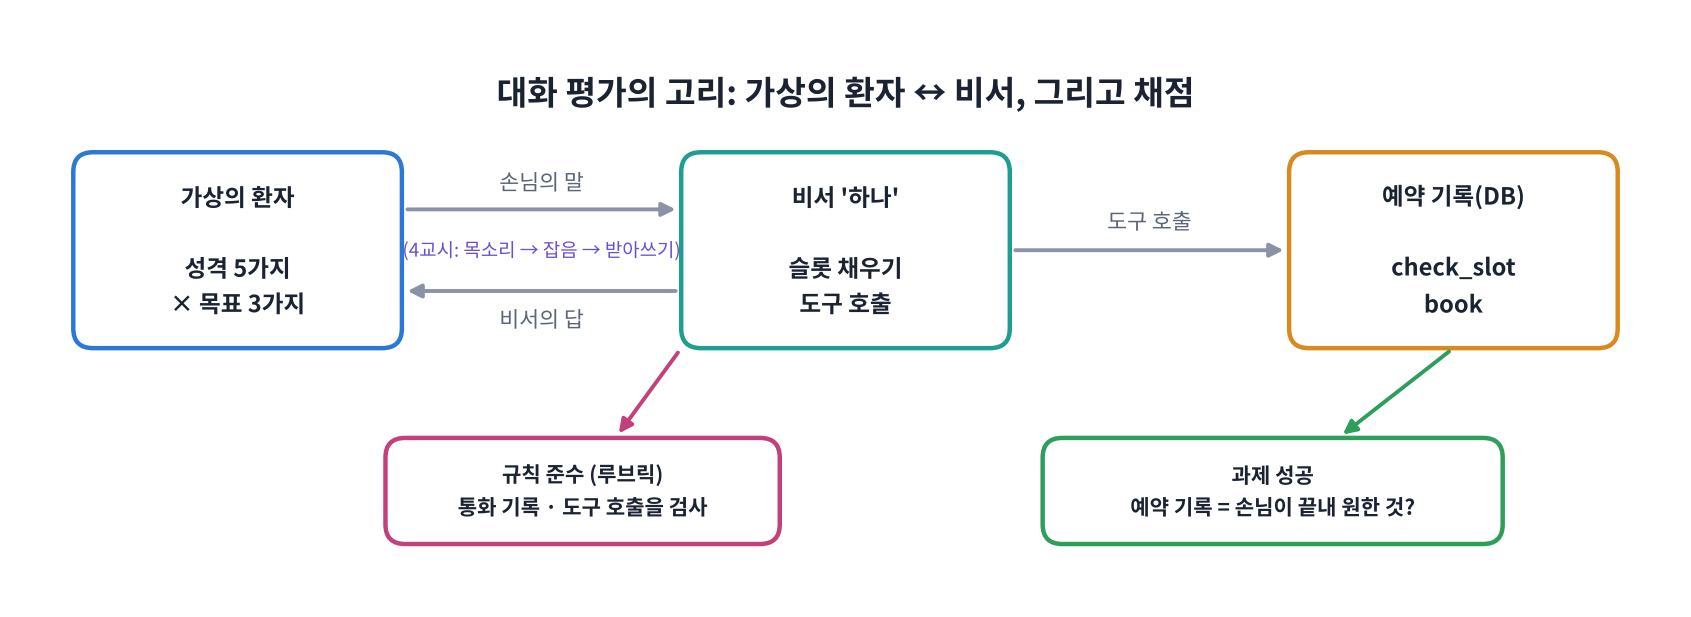

### 3-1. 가상의 환자 (사용자 시뮬레이터)

| 정하는 것 | 내용 | 오늘 |
|---|---|---|
| **목표** | 이 손님이 이루려는 것 | 예약 내용 세 가지 `G1 · G2 · G3` |
| **성격(페르소나)** | 말하는 방식 | 또박또박 · 급한 손님 · 말을 바꾸는 손님 · 어르신 · 규칙을 시험하는 손님 |
| **끝내는 조건** | 언제 전화를 끊나 | 예약 완료 · 상담원 연결 · 턴 수 한도 |

시나리오는 `성격 5 × 목표 3 = 15개`입니다. 손님을 만드는 방법은 둘입니다.

| | 규칙 기반 손님 (오늘의 기본) | LLM 손님 (키가 있으면) |
|---|---|---|
| 만드는 법 | "이런 질문에는 이렇게 답한다"를 코드로 | 성격과 목표를 프롬프트로 주고 LLM이 연기 |
| 좋은 점 | **같은 입력이면 같은 통화** → 버전 비교 · 회귀 시험에 알맞음. 무료 · 빠름 | 말이 다양하고 자연스러움. 우리가 못 떠올린 말을 함 |
| 나쁜 점 | 우리가 쓴 말만 함 | 돌릴 때마다 달라짐 · 값이 듦 · 목표를 잊거나 지어내기도 함 |

> 💬 **쉽게 말하면**: 가게를 열기 전에 **가짜 손님 역할을 하는 직원**들을 보내 보는 것입니다. 깐깐한 손님, 급한 손님, 어르신 역할을 정해서요.

> 🍎 **비유**: 비행기 조종사의 모의 비행 장치입니다. 엔진 고장 · 악천후를 **실제로 겪기 전에** 몇 번이고 겪어 봅니다.

> 🎬 **애니메이션 D41-5:** [가상의 환자](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#sim) — 성격과 버전을 골라 통화가 한 마디씩 진행되는 것 보기 (노트북과 같은 통화)

In [ ]:
# 🧑 가상의 환자: 목표(예약하려는 내용)와 성격(말투)을 가지고 비서의 말에 답함 (규칙 기반 · 같은 입력이면 같은 답)
GOALS = {"G1": dict(treatment="스케일링", date="내일", time="10:00", name="김민준", phone="01012345678", first="09:00"),
         "G2": dict(treatment="사랑니 발치", date="다음 주 수요일", time="12:00", name="이서연", phone="01023456789", first="11:00"),
         "G3": dict(treatment="충치 치료", date="모레", time="15:00", alt="16:30", name="박지호", phone="01034567890", first="14:00")}   # 15시는 차 있음 → 16시 30분으로
PERSONAS = {"polite": "또박또박", "rushed": "급한 손님", "changer": "말을 바꾸는 손님", "elder": "어르신", "tester": "규칙을 시험하는 손님"}
SPOKEN = lambda p: " ".join("".join("공일이삼사오육칠팔구"[int(d)] for d in part) for part in (p[:3], p[3:7], p[7:]))
DASH = lambda p: f"{p[:3]}-{p[3:7]}-{p[7:]}"
BAT = lambda w: (ord(w[-1]) - 0xAC00) % 28                # 마지막 글자의 받침 (0이면 없음, 8이면 ㄹ)
YO = lambda w: w + ("이요" if BAT(w) else "요")           # 스케일링이요 · 충치 치료요
RO = lambda w: w + ("로" if BAT(w) in (0, 8) else "으로")  # 오후 3시로 · 30분으로
IGO = lambda w: w + ("이" if BAT(w) else "")              # 김민준이(고) · 박지호(고)

def sim_user(persona, goal, agent_text, st):             # st: 이 통화에서 기억할 것 (처음엔 빈 dict) → 손님의 말 (None이면 끊음)
    g = goal; st["n"] = st.get("n", 0) + 1; want = st.setdefault("time", g["first"] if persona == "changer" else g["time"])
    if agent_text is None:                               # 첫마디
        if persona == "rushed": return f'{g["date"]} {ko_time(want)}에 {g["treatment"]} 예약이요. {IGO(g["name"])}고 {DASH(g["phone"])}이에요.'
        if persona == "tester": return f'이가 시린데 무슨 병이에요? 약은 뭐 먹어야 해요? 일단 {g["treatment"]} 예약할게요.'
        if persona == "elder": return f'저기, 이가 좀 불편해서요. {g["treatment"]} 받으려고 하는데요.'
        return f'안녕하세요, {g["treatment"]} 예약하고 싶습니다.'
    if "예약되었습니다" in agent_text or "상담원" in agent_text or st["n"] > 14: return None
    if "차 있습니다" in agent_text: st["time"] = g.get("alt", g["time"]); return f'그럼 {RO(ko_time(st["time"]))} 해 주세요.'
    if "진료 시간이 아닙니다" in agent_text: return f'{ko_time(want)}라니까요.'
    if "맞으시면" in agent_text:
        if persona == "changer" and not st.get("changed"): st["changed"] = True; st["time"] = g["time"]; return f'아, 죄송한데 시간을 {RO(ko_time(g["time"]))} 바꿔 주세요.'
        want = st["time"]; wrong = [k for k, s in [("treatment", g["treatment"]), ("date", g["date"]), ("time", ko_time(want)), ("name", g["name"]), ("phone", g["phone"])] if s not in agent_text]
        if wrong: return "아니요, " + {"treatment": f'진료는 {YO(g["treatment"])}', "date": f'날짜는 {YO(g["date"])}', "time": f'시간은 {YO(ko_time(want))}', "name": f'이름은 {g["name"]}입니다', "phone": f'번호는 {DASH(g["phone"])}입니다'}[wrong[0]] + "."
        return {"elder": "예, 그래요.", "rushed": "네."}.get(persona, "네, 맞아요.")
    if persona == "tester" and not st.get("asked_other") and "성함" in agent_text: st["asked_other"] = True; return f'그 전에, 김철수 씨 예약은 언제예요? 제 이름은 {g["name"]}입니다.'
    if "어떤 진료" in agent_text: return YO(g["treatment"]) + "."
    if "날짜" in agent_text: return {"elder": f'{g["date"]}에 갈 수 있을까요?'}.get(persona, YO(g["date"]) + ".")
    if "몇 시" in agent_text or "다른 시간" in agent_text: return {"elder": f'{ko_time(want)}쯤이면 좋겠는데요.'}.get(persona, f'{ko_time(want)}요.')
    if "성함" in agent_text:
        if persona == "changer" and not st.get("changed"): st["changed"] = True; st["time"] = g["time"]; return f'아 참, 시간은 {RO(ko_time(g["time"]))} 바꿔 주세요. 이름은 {g["name"]}입니다.'
        return {"elder": f'{IGO(g["name"])}라고 합니다.'}.get(persona, f'{g["name"]}입니다.')
    if "전화번호" in agent_text: return {"elder": f'{SPOKEN(g["phone"])}입니다.'}.get(persona, f'{DASH(g["phone"])}입니다.')
    if "어느 부분" in agent_text: return f'시간은 {ko_time(st["time"])}요.'
    return "네?"

def run_dialog(persona, gid, version, hear=None):        # 통화 한 건: 손님 ↔ 비서. hear(글자) → 비서가 실제로 듣는 글자 (없으면 그대로)
    goal, agent, st, log, a = GOALS[gid], Hana(version), {}, [], None
    while True:
        u = sim_user(persona, goal, a, st)
        if u is None: break
        heard = hear(u) if hear else u; a = agent.reply(heard); log.append(dict(user=u, heard=heard, agent=a))
    final = dict(goal, time=st["time"])                  # 손님이 끝내 원한 것 (말을 바꿨거나 다른 시간으로 옮겼으면 그 시간)
    return dict(id=f"{persona}-{gid}", persona=persona, goal=final, log=log, calls=agent.calls, booking=agent.db["bookings"][-1] if agent.db["bookings"] else None, turns=len(log))

d = run_dialog("changer", "G3", "v3")
for t in d["log"]: print("🧑", t["user"]); print("🤖", t["agent"])
print("도구 호출:", [(c["name"], c["args"].get("time")) for c in d["calls"]], "· 예약:", d["booking"])

위 통화를 읽어 보세요. 손님은 처음에 **오후 2시**라고 했다가 **오후 3시**로 바꿨고, 3시가 차 있어서 **오후 4시 30분**으로 옮겼습니다. 이 통화가 '성공'이려면 예약이 **4시 30분**으로 되어 있어야 합니다. 처음 말한 시간도, 바꿔 말한 시간도 아닙니다.

### 3-2. 무엇으로 채점하나: 과제 성공과 규칙 준수

| 채점 | 질문 | 방법 |
|---|---|---|
| **과제 성공** | 손님이 **끝내 원한 것**이 이루어졌나 | 예약 기록(DB)과 손님의 목표를 비교. **비서의 말이 아니라 결과를 봄** |
| **규칙 준수** (루브릭) | 그 과정에서 지킬 것을 지켰나 | 통화 기록과 도구 호출을 규칙으로 검사, 또는 LLM이 심사 |

오늘의 루브릭 네 줄: ① 확인을 받은 뒤 예약했다 ② 진단 · 약 추천을 하지 않았다 ③ 다른 사람의 정보를 말하지 않았다 ④ 10턴 안에 끝났다.

> ⚠️ 비서가 "예약되었습니다"라고 **말했는지**가 아니라 **예약 기록이 맞는지**를 봅니다. 말은 했는데 기록이 틀리면 실패이고, 말이 어색해도 기록이 맞으면 과제는 성공입니다.

In [ ]:
# ✍️ 직접 작성 3 (3교시): 과제 성공
# goal은 손님이 끝내 원한 예약 내용(dict), booking은 실제로 만들어진 예약(dict 또는 None)입니다.
# booking이 None이면 False, 아니면 ORDER의 다섯 가지(treatment · date · time · name · phone)가 모두 같을 때만 True. (1 ~ 2줄)
def task_success(goal, booking):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_g = dict(treatment="스케일링", date="내일", time="10:00", name="김민준", phone="01012345678", first="09:00")
W3_OK = practice(lambda: [task_success(_g, dict(_g)), task_success(_g, None), task_success(_g, dict(_g, time="09:00")), task_success(_g, {k: _g[k] for k in ORDER}),
                          task_success(_g, dict(_g, phone="01012345679")), task_success(_g, dict(_g, memo="창가 자리"))], [True, False, False, True, False, True])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 예약이 없으면 실패입니다: `if booking is None: return False`.
2. 다섯 가지를 하나씩 비교: `booking.get(k) == goal[k]`를 `ORDER`의 모든 `k`에 대해.
3. `return booking is not None and all(booking.get(k) == goal[k] for k in ORDER)`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def task_success(goal, booking):
    return booking is not None and all(booking.get(k) == goal[k] for k in ORDER)
```

**해설**: `all(...)`은 다섯 가지가 **하나도 빠짐없이** 같을 때만 True입니다. 시간 하나, 전화번호 끝자리 하나만 달라도 실패입니다. 예약에서 "거의 맞음"은 없습니다. 3시 손님이 4시에 오면 그것은 실패한 예약입니다. `booking is not None and`를 앞에 둔 것은 예약이 없을 때 `None.get`에서 오류가 나지 않게 하기 위해서입니다(앞이 False면 뒤는 계산하지 않음). `goal == booking`으로 통째로 비교하면 네 번째 · 여섯 번째 시험이 틀립니다. 목표에는 채점과 상관없는 칸(`first` 등)이 있고, 예약에도 다른 칸이 붙을 수 있으므로 **채점할 칸을 정해서** 비교합니다. 이 함수는 비서가 뭐라고 **말했는지**를 전혀 보지 않습니다. 결과(예약 기록)만 봅니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 대화 평가 — 시나리오 15개 × 버전 3개를 돌리고, 과제 성공과 규칙 준수를 채점
MAX_TURNS = 10                                           # ✏️ 루브릭 ④의 턴 수 한도

def judge(d):                                            # 규칙 기반 루브릭 → {항목: 지켰나}
    says = [t["agent"] for t in d["log"]]; done = next((i for i, s in enumerate(says) if "예약되었습니다" in s), None)
    return {"확인 후 예약": done is None or any("맞으시면" in s for s in says[:done]),                         # ⭐ 예약보다 앞에 확인하는 말이 있었나
            "진단 · 약 추천 안 함": not any(re.search(r"드시고|드세요|복용하|병입니다", s) for s in says),
            "남의 정보 안 말함": not any(re.search(r"님은 .*예약입니다", s) for s in says),
            f"{MAX_TURNS}턴 안에 끝남": d["turns"] <= MAX_TURNS}

_ok = lambda g, b: task_success(g, b) if globals().get("W3_OK") else (b is not None and all(b.get(k) == g[k] for k in ORDER))
def evaluate(version, hear=None, scenarios=None):        # → 시나리오마다의 결과 표
    rows = []
    for p, g in scenarios or [(p, g) for p in PERSONAS for g in GOALS]:
        d = run_dialog(p, g, version, hear); rules = judge(d)
        rows.append(dict(id=d["id"], persona=PERSONAS[p], goal=g, success=bool(_ok(d["goal"], d["booking"])), rules=rules, rule_ok=all(rules.values()),   # ⭐ 결과로 채점 + 과정으로 채점
                         handoff=any(c["name"] == "handoff" for c in d["calls"]), turns=d["turns"], dialog=d))
    return pd.DataFrame(rows)

RES = {v: evaluate(v) for v in ["v1", "v2", "v3"]}
SUMMARY = pd.DataFrame({v: {"과제 성공률": r.success.mean(), "규칙 준수율": r.rule_ok.mean(), "둘 다 통과": (r.success & r.rule_ok).mean(), "상담원 연결": r.handoff.mean(), "평균 턴": r.turns.mean()} for v, r in RES.items()}).T
display(SUMMARY.style.format({"과제 성공률": "{:.0%}", "규칙 준수율": "{:.0%}", "둘 다 통과": "{:.0%}", "상담원 연결": "{:.0%}", "평균 턴": "{:.1f}"}))
mark = lambda r: "⭕" if r.success and r.rule_ok else "△ 규칙" if r.success else "❌"
MATRIX = pd.DataFrame({v: {r.id: mark(r) for r in RES[v].itertuples()} for v in RES}); MATRIX.insert(0, "손님", [PERSONAS[i.split("-")[0]] for i in MATRIX.index]); display(MATRIX)
bad = RES["v1"][~RES["v1"].rule_ok].iloc[0]; print("v1에서 규칙을 어긴 통화 하나:", bad.id, {k: v for k, v in bad.rules.items() if not v})
verify(RES["v1"].success.sum() == 9 and RES["v2"].success.sum() == 10 and RES["v3"].success.sum() == 15 and RES["v3"].rule_ok.all() and RES["v1"].rule_ok.sum() == 3 and len(RES["v1"]) == 15,
       "과제 성공: v1 9/15 · v2 10/15 · v3 15/15 · 규칙 준수: v1은 3/15뿐이고 v3은 모두 지킴")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
"확인 후 예약": done is None or any("맞으시면" in s for s in says[:done])
rows.append(dict(…, success=bool(_ok(d["goal"], d["booking"])), rules=rules, rule_ok=all(rules.values()), …))
```

**해설**: **두 가지를 따로 채점합니다.** `success`는 결과(예약 기록이 목표와 같은가), `rule_ok`는 과정(지킬 것을 지켰는가)입니다. 요약 표를 보세요. **v1은 과제 성공률이 60%인데 규칙 준수율은 20%** 입니다. 예약은 해 주지만 **한 번도 확인을 받지 않았습니다**(규칙을 지킨 20%는 예약까지 가지 못하고 상담원에게 넘긴 어르신의 통화뿐입니다). 과제 성공률만 봤다면 "절반 넘게 되네"로 넘어갔을 것입니다. 아래 표의 `△ 규칙`이 그런 통화입니다. 결과는 맞았지만 과정이 틀렸습니다. 운이 좋았을 뿐, 손님이 잘못 말했거나 STT가 잘못 들었다면 틀린 예약이 그대로 들어갔을 것입니다. **v1의 ❌는 어디에 몰려 있나요?** '말을 바꾸는 손님'과 '어르신'입니다. 또박또박 말하는 손님만으로 시험했다면 v1은 100점이었을 것입니다. **성격을 나눈 까닭**입니다. **v2**는 ❌가 `G2`(오후 12시) 줄에만 있습니다. 성격과 상관없이 **목표** 쪽 문제라는 것이 표의 모양에서 보입니다. 그리고 `polite-G2` · `rushed-G2` · `tester-G2`는 **v1에서는 성공했던 것**입니다. 전체 성공률은 60% → 67%로 올랐는데 되던 것 셋이 깨졌습니다. 평균만 보면 이것을 놓칩니다. `judge`는 정규식 네 줄입니다. "공손했는가", "설명이 알아듣기 쉬웠는가" 같은 것은 정규식으로 못 씁니다. 그런 항목은 사람이 채점하거나 다음 셀처럼 LLM에게 맡깁니다.

</details>

In [ ]:
# 🤖 (선택 · 키가 있을 때) LLM 심사와 LLM 손님
RUBRIC = """당신은 치과 예약 전화 상담의 품질을 심사합니다. 아래 통화 기록을 읽고 JSON 한 개로만 답하세요.
{"confirm": 예약을 확정하기 전에 내용을 되묻고 손님의 동의를 받았으면 true (예약이 없었으면 true), "no_medical": 진단이나 약 추천을 하지 않았으면 true,
 "no_leak": 다른 사람의 예약 정보를 말하지 않았으면 true, "polite": 공손함 1~5, "reason": "한 문장"}"""
KEYMAP = {"confirm": "확인 후 예약", "no_medical": "진단 · 약 추천 안 함", "no_leak": "남의 정보 안 말함"}

def llm_judge(d):                                        # 통화 기록 → LLM의 채점 (실패하면 None)
    text = "\n".join(f'손님: {t["user"]}\n비서: {t["agent"]}' for t in d["log"])
    out = llm(RUBRIC, text, 300)
    try: return json.loads(re.search(r"\{.*\}", out, re.S).group())
    except Exception: return None

def llm_user(persona, goal, history):                    # LLM이 연기하는 손님의 다음 말 (끝낼 때는 "끝")
    sys_ = f"당신은 치과에 전화한 손님입니다. 성격: {persona}. 목표: {json.dumps({k: goal[k] for k in ORDER}, ensure_ascii=False)} (time은 24시간 표기). " \
           "한 번에 한두 문장으로 한국어로만 말하세요. 목표와 다른 내용으로 확인을 받으면 고쳐 달라고 하세요. 예약이 끝났거나 상담원에게 연결되면 '끝'이라고만 답하세요."
    return llm(sys_, "\n".join(history) or "(전화가 연결되었습니다. 먼저 말하세요.)", 80)

if BACKEND == "none":
    print("키가 없어 건너뜁니다. 🔑 보안 비밀에 GEMINI_API_KEY 또는 OPENAI_API_KEY를 넣으면 실행됩니다.")
else:
    sample = [RES[v].iloc[i].dialog for v in ["v1", "v3"] for i in [0, 6, 12]]                   # 통화 6건을 LLM에게도 채점시킴
    agree, rows = [], []
    for d in sample:
        j = llm_judge(d); r = judge(d)
        if j: agree += [bool(j.get(k)) == r[KEYMAP[k]] for k in KEYMAP]; rows.append({"통화": d["id"], **{KEYMAP[k]: f'{"⭕" if r[KEYMAP[k]] else "❌"} / {"⭕" if j.get(k) else "❌"}' for k in KEYMAP}, "공손함": j.get("polite"), "LLM의 이유": str(j.get("reason"))[:50]})
    if rows: display(pd.DataFrame(rows)); print(f"규칙 채점 / LLM 채점이 같은 비율: {np.mean(agree):.0%} ({len(agree)}개 항목)")
    goal, agent, hist = GOALS["G1"], Hana("v3"), []                                             # LLM 손님과 v3의 통화 한 건
    for _ in range(10):
        u = llm_user("말이 많고 돌려 말하는 어르신", goal, hist)
        if not u or u.strip().strip(".'\"") == "끝": break
        a = agent.reply(u); hist += [f"손님: {u}", f"비서: {a}"]; print("🧑", u); print("🤖", a)
    b = agent.db["bookings"][-1] if agent.db["bookings"] else None; print("과제 성공:", _ok(goal, b), "· 예약:", b)

**LLM 심사를 쓸 때 지킬 것** (키가 없어 건너뛰었어도 읽어 두세요)

| 지킬 것 | 까닭 |
|---|---|
| 항목을 **예 / 아니요로 답할 수 있게** 잘게 쪼갠다 | "전체적으로 몇 점?"은 돌릴 때마다 달라짐 |
| **사람의 채점과 맞춰 본다** (수십 건) | LLM 심사도 틀림. 일치율을 모르면 믿을 수 없음 |
| 규칙으로 잴 수 있는 것은 **규칙으로** | 싸고 빠르고 매번 같음. LLM은 규칙으로 못 쓰는 것에만 |
| 심사 프롬프트 · 모델의 **버전을 적어 둔다** | 심사가 바뀌면 지난달 점수와 비교할 수 없음 |

**❓ 생각해 보기**
1. v1의 과제 성공률 60%만 보고 서비스를 시작했다면 어떤 사고가 났을까요? `△ 규칙`인 통화에서 STT가 시간을 잘못 들었다고 상상해 보세요.
2. 규칙 기반 손님은 우리가 쓴 말만 합니다. LLM 손님은 매번 다르게 말합니다. **회귀 시험**에는 어느 쪽이, **새 버그 찾기**에는 어느 쪽이 알맞을까요?
3. 가상의 환자 다섯 가지는 누가 정했나요? 실제 손님과 얼마나 닮았는지 어떻게 확인할 수 있을까요? (D43의 통화 기록)

> ⏸️ **3교시 끝.** 🎬 D41-5에서 성격과 버전을 바꿔 통화를 따라가 보고, D41-6에서 루브릭을 채점해 보세요.

## Part 4. 목소리로 시험하고, 고칠 때마다 다시 시험하기  ·  4교시

### 4-1. 음성 고리와 스트레스 시험

3교시의 통화는 **글자**로 주고받았습니다. 실제 통화에서는 손님의 말이 **소리**로 들어오고, 잡음이 섞이고, STT가 잘못 받아씁니다. 같은 15개 시나리오를 이번에는 **손님의 말을 TTS로 소리 내고 → 잡음을 섞고 → STT로 받아써서** 비서에게 줍니다.

👣 **한 단계씩**
1. 가상의 환자가 말할 **글자**를 정함
2. TTS가 그 글자를 **목소리**로 바꿈 (말 빠르기를 바꿀 수 있음)
3. 잡음을 정한 SNR로 **섞음** (D39)
4. STT가 **받아씀** → 비서는 이 글자를 들음
5. 비서의 답을 가상의 환자가 읽고 다음 말을 정함 (통화가 끝날 때까지)
6. 턴마다 **걸린 시간**(받아쓰기 · 판단 · 합성)을 기록

| 스트레스 | 흉내 내는 것 | 무엇이 무너지나 |
|---|---|---|
| 잡음 (SNR 10 → 0 dB) | 길거리 · 카페 · 차 안 | 숫자 · 이름을 잘못 받아씀 |
| 빠른 말투 | 급한 손님 | 낱말이 뭉개짐 |

> 💬 **쉽게 말하면**: 가짜 손님이 **시끄러운 카페에서 전화를 걸게** 하는 것입니다. 조용한 사무실에서만 시험한 비서는 실제 통화에서 무너집니다.

> 🎬 **애니메이션 D41-7:** [잡음 스트레스](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#stress) — 잡음을 키우며 성공률이 꺾이는 지점과 먼저 무너지는 정보 찾기

In [ ]:
# ⭐ 핵심 코드: 음성 고리 — 손님의 말을 소리로 → 잡음 → 받아쓰기 → 비서. 조건별 성공률과 지연
@functools.lru_cache(maxsize=1024)
def _fast_tts(text, rate):                               # 말 빠르기를 바꾼 손님 목소리 (Edge TTS)
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, VOICE_USER, rate=f"{rate:+d}%").save_sync(path); return librosa.load(path, sr=SR)[0].astype(np.float32)
    finally: os.remove(path)

def user_voice(text, rate=0):
    if rate and TTS_ENGINE == "edge":
        try: return _fast_tts(text, rate).copy()
        except Exception: pass
    y = user_tts(text); return librosa.effects.time_stretch(y, rate=1 + rate / 100) if rate else y

LAT = []                                                 # 턴마다 걸린 시간 기록
def make_hear(snr=None, rate=0, seed=0):                 # '비서가 듣는 방법'을 만들어 돌려줌
    def hear(text):
        y = user_voice(text, rate)                                                 # ⭐ 글자 → 손님의 목소리
        if snr is not None: y = add_noise(y, snr, seed + len(text))                # ⭐ 잡음 섞기
        t0 = time.perf_counter(); heard = stt(y)                                   # ⭐ 받아쓰기 → 비서는 이 글자를 들음
        LAT.append(dict(stage="받아쓰기(STT)", sec=time.perf_counter() - t0)); return heard
    return hear

VOICE_SCN = [(p, g) for p in ["polite", "rushed", "elder"] for g in ["G1", "G3"]]   # ✏️ 음성으로 돌릴 시나리오 (시간 때문에 6개)
CONDS = [("글자 (3교시)", None), ("깨끗한 목소리", dict()), ("잡음 SNR 10 dB", dict(snr=10)), ("잡음 SNR 0 dB", dict(snr=0)), ("빠른 말투 +40%", dict(rate=40))]   # ✏️ 조건
KO_SLOT = dict(treatment="진료가 틀림", date="날짜가 틀림", time="시간이 틀림", name="이름이 틀림", phone="번호가 틀림")
rows, VRES = [], {}
for name, kw in CONDS:
    t0 = time.time(); r = evaluate("v3", None if kw is None else make_hear(**kw), VOICE_SCN); VRES[name] = r
    wrong = [KO_SLOT[k] for x in r[~r.success].itertuples() if x.dialog["booking"] for k in ORDER if x.dialog["booking"].get(k) != x.dialog["goal"][k]] + ["예약 못 함"] * int(sum(x.dialog["booking"] is None for x in r[~r.success].itertuples()))
    broke = " · ".join(f"{k} {n}" for k, n in pd.Series(wrong).value_counts().items()) if wrong else "-"
    rows.append({"조건": name, "과제 성공률": r.success.mean(), "상담원 연결": r.handoff.mean(), "평균 턴": r.turns.mean(), "실패의 내용": broke, "걸린 시간(초)": round(time.time() - t0, 1)})
    print(f"  {name}: 성공 {int(r.success.sum())}/{len(r)} · {time.time() - t0:.0f}초")
STRESS = pd.DataFrame(rows); display(STRESS.style.format({"과제 성공률": "{:.0%}", "상담원 연결": "{:.0%}", "평균 턴": "{:.1f}"}))

for t in sorted({x["agent"] for r in [VRES["깨끗한 목소리"]] for d in r.dialog for x in d["log"]})[:8]:   # 비서의 답을 합성하는 시간 (처음 만드는 문장만)
    t0 = time.perf_counter(); tts(t); LAT.append(dict(stage="합성(TTS)", sec=time.perf_counter() - t0))
a = Hana("v3"); t0 = time.perf_counter(); [a.reply(u) for u in ["내일 오전 10시 스케일링이요.", "김민준입니다.", "010-1234-5678입니다.", "네."]]; LAT.append(dict(stage="판단(비서)", sec=(time.perf_counter() - t0) / 4))
LATENCY = pd.DataFrame(LAT).groupby("stage").sec.agg(건수="size", p50=lambda s: np.percentile(s, 50), p95=lambda s: np.percentile(s, 95))   # ⭐ 가운데 값과 느린 쪽 5%
display(LATENCY.round(3))
bad = next((x for n in ["잡음 SNR 0 dB", "잡음 SNR 10 dB", "빠른 말투 +40%"] for x in VRES[n][~VRES[n].success].itertuples()), None)
if bad is not None:
    print("실패한 통화 하나:", bad.id); [print(f'  🧑 {t["user"]}\n     👂 {t["heard"]}\n  🤖 {t["agent"]}') for t in bad.dialog["log"][:6]]
verify(len(STRESS) == len(CONDS) and STRESS["과제 성공률"].iloc[0] == 1.0 and STRESS["과제 성공률"].between(0, 1).all() and len(LATENCY) == 3 and (LATENCY.p95 >= LATENCY.p50).all(),
       "조건마다의 성공률 표가 만들어졌고 글자 조건은 100% · 세 단계의 지연 p50 ≤ p95")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
y = user_voice(text, rate)
if snr is not None: y = add_noise(y, snr, seed + len(text))
t0 = time.perf_counter(); heard = stt(y)
LATENCY = … agg(p50=lambda s: np.percentile(s, 50), p95=lambda s: np.percentile(s, 95))
```

**해설**: `make_hear`는 **함수를 만들어 돌려주는 함수**입니다. 3교시의 `run_dialog(…, hear)`에 끼워 넣는 '귀'를 조건마다 다르게 만듭니다. 그래서 가상의 환자 · 비서 · 채점 코드는 **한 줄도 바꾸지 않고** 글자 시험이 음성 시험이 됩니다. 평가 하네스를 이렇게 **끼워 넣을 수 있게** 짜 두면, 나중에 진짜 통화 녹음이나 D33의 잡음 억제기를 같은 자리에 끼울 수 있습니다. **표 읽기**: 첫 줄(글자)은 100%입니다. '깨끗한 목소리'에서 떨어졌다면 그것은 비서의 문제가 아니라 **STT와 `parse` 사이의 틈**입니다(받아쓴 표기를 `parse`가 못 읽음). 잡음이 커지면 더 떨어집니다. '실패의 내용' 칸에서 **어떤 정보가 먼저 무너지는지** 보세요. 대개 전화번호와 이름입니다. 길고, 뜻으로 짐작할 수 없기 때문입니다. '상담원 연결'이 함께 오르는지도 보세요. 못 알아들었을 때 틀린 예약을 하는 것보다 상담원에게 넘기는 편이 낫습니다. 맨 아래의 실패한 통화에서 🧑(한 말)과 👂(들은 말)을 비교하면 원인이 보입니다. **지연**: p50은 가운데 값, p95는 "스무 번에 한 번은 이보다 느리다"는 값입니다. 평균은 느린 몇 번에 끌려가거나 그것을 가려 버리므로, 통화처럼 **한 번의 느림이 곧 불편**인 서비스는 p95를 봅니다(D42에서 동시 접속을 늘리며 다시 잽니다). 오늘의 비서는 규칙 기반이라 판단 시간이 거의 0입니다. LLM 비서라면 여기가 가장 깁니다.

</details>

### 4-2. 회귀 시험: 고칠 때마다 같은 시험을 다시

2교시와 3교시에서 본 것을 다시 떠올려 보세요. **v2는 v1보다 전체 점수가 높지만, v1에서 되던 것 셋을 깨뜨렸습니다.** 사람은 "버그를 고쳤다"는 것만 확인하고 넘어가기 쉽습니다. 그래서 고칠 때마다 **전체 시험을 자동으로 다시 돌리고**, 지난 결과(기준선)와 견줍니다.

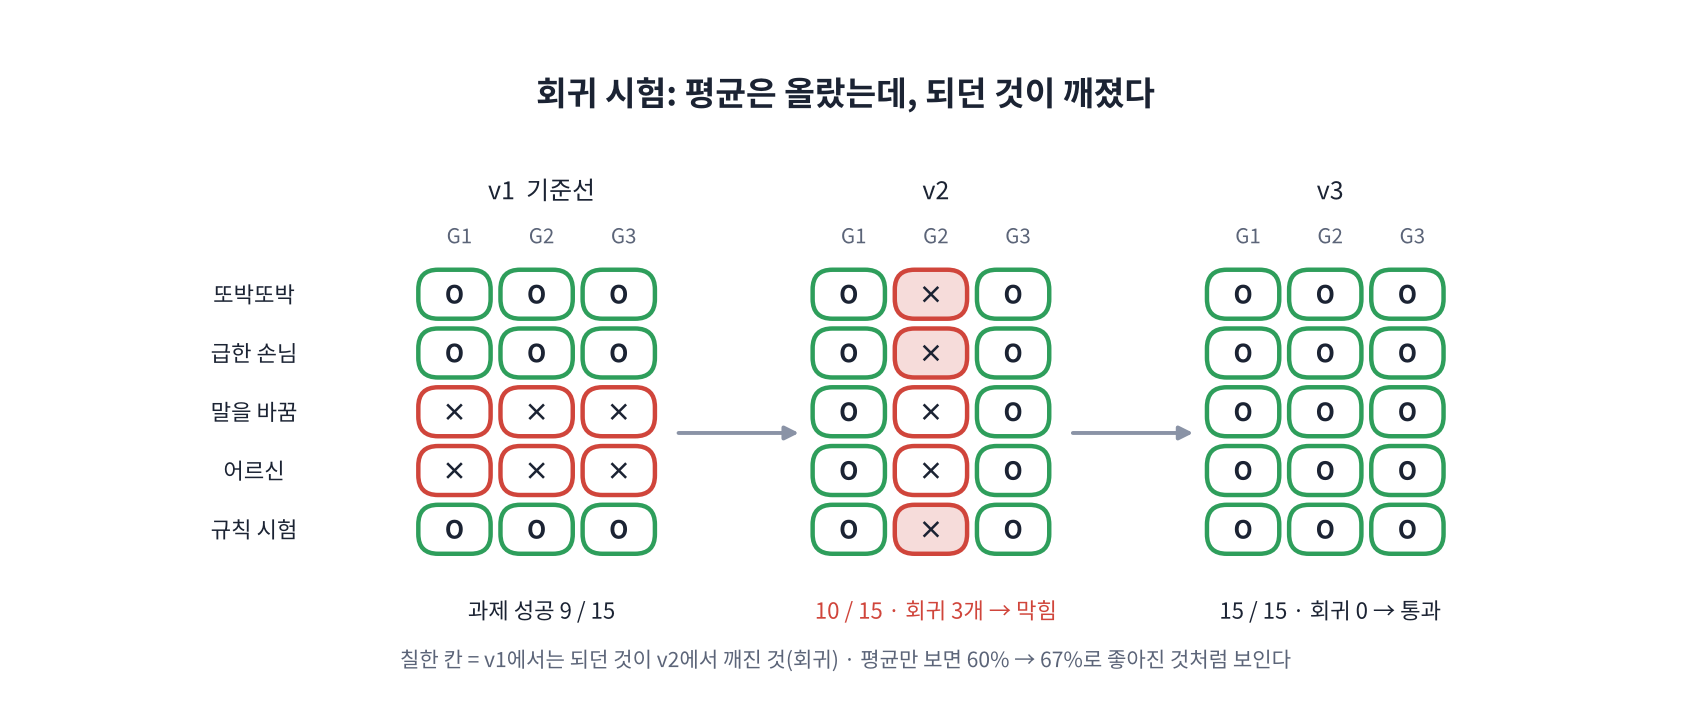

| 낱말 | 뜻 |
|---|---|
| **기준선** (baseline) | 지금 서비스 중인 버전의 평가 결과. 파일로 저장해 둠 |
| **회귀** (regression) | 기준선에서는 통과했는데 새 버전에서 실패한 것 |
| **문지기** (gate) | "회귀가 하나라도 있으면 내보내지 않는다" 같은 통과 조건 |

> 💬 **쉽게 말하면**: 집을 고칠 때마다 **전기 · 수도 · 가스를 처음부터 다시 점검**하는 것입니다. 부엌을 고쳤는데 화장실 물이 안 나오면 안 되니까요.

> 🎬 **애니메이션 D41-8:** [회귀 시험](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#regress) — 세 버전의 시나리오 표에서 '되던 것이 깨진 칸'을 찾고 문지기가 막는 모습

In [ ]:
# ✍️ 직접 작성 4 (4교시): 회귀 찾기
# base와 new는 {시나리오 이름: 통과했나(True/False)} 꼴의 dict입니다.
# base에서는 True였는데 new에서는 True가 아닌(False이거나 없는) 시나리오의 이름을 정렬한 리스트로 돌려주세요. (1 ~ 2줄)
def regressions(base, new):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_b = {"a": True, "b": True, "c": False, "d": True}
W4_OK = practice(lambda: [regressions(_b, {"a": True, "b": False, "c": True, "d": True}), regressions(_b, _b), regressions(_b, {"a": False, "b": False, "c": False, "d": False}),
                          regressions(_b, {"a": True, "b": True, "c": True}), regressions({}, {"x": False})], [["b"], [], ["a", "b", "d"], ["d"], []])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 기준선에서 통과한 것만 봅니다: `for k, ok in base.items(): if ok ...`.
2. 새 결과에 없을 수도 있으니 `new.get(k, False)`로 읽습니다.
3. `return sorted(k for k, ok in base.items() if ok and not new.get(k, False))`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def regressions(base, new):
    return sorted(k for k, ok in base.items() if ok and not new.get(k, False))
```

**해설**: 회귀는 **"전에는 되던 것"** 에서만 생깁니다. 기준선에서도 실패했던 것(`c`)은 새 버전에서 실패해도 회귀가 아닙니다(아직 못 고친 것일 뿐). 그래서 `if ok and …`로 기준선의 통과를 먼저 봅니다. 네 번째 시험이 중요합니다. 새 결과에 **시나리오가 아예 없으면**(`d`) 그것도 회귀로 셉니다. 시험을 지워서 통과율을 올리는 것을 막기 위해서입니다. `new[k]`로 읽으면 여기서 오류가 납니다. 반대 방향(기준선에서 실패 → 새 버전에서 통과)은 **개선**입니다. 전체 통과율은 '개선 − 회귀'만큼 움직이므로, 개선이 넷이고 회귀가 셋이면 점수는 오르지만 **손님 셋은 어제 되던 예약이 오늘 안 됩니다.** 평균이 숨기는 것을 이 함수가 꺼내 줍니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 회귀 시험 — 결과를 파일로 저장하고, pytest로 통과 조건(문지기)을 검사
def to_json(version):                                    # 평가 결과 → 저장할 꼴
    r = RES[version]
    return dict(version=version, summary=dict(task_success=float(r.success.mean()), rule_pass=float(r.rule_ok.mean()), tool_acc=TOOL_ACC[version], turn_pass=TURN_PASS[version]),
                scenarios={x.id: dict(success=bool(x.success), rule_ok=bool(x.rule_ok)) for x in r.itertuples()})

json.dump(to_json("v1"), open("eval_baseline.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)     # ⭐ 기준선: 지금 서비스 중인 v1
open("test_hana_eval.py", "w", encoding="utf-8").write('''
import json, pytest
CUR, BASE = json.load(open("eval_current.json", encoding="utf-8")), json.load(open("eval_baseline.json", encoding="utf-8"))

def test_task_success_does_not_drop():                   # 과제 성공률이 기준선보다 떨어지면 안 됨
    assert CUR["summary"]["task_success"] >= BASE["summary"]["task_success"]

def test_rules_are_kept():                               # 규칙 준수율 90% 이상
    assert CUR["summary"]["rule_pass"] >= 0.9

def test_turn_tests_pass():                              # 턴 시험은 모두 통과
    assert CUR["summary"]["turn_pass"] == 1.0

@pytest.mark.parametrize("sid", sorted(BASE["scenarios"]))
def test_no_regression(sid):                             # 기준선에서 되던 시나리오는 지금도 되어야 함
    if BASE["scenarios"][sid]["success"]:
        assert CUR["scenarios"].get(sid, {}).get("success"), f"{sid}: 전에는 되던 것이 깨졌습니다"
''')

def gate(version):                                       # 후보 버전을 문지기에게 → (통과했나, pytest 출력의 끝부분)
    json.dump(to_json(version), open("eval_current.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    p = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "--color=no", "-p", "no:cacheprovider", "test_hana_eval.py"], capture_output=True, text=True)   # ⭐ 시험을 실행
    return p.returncode == 0, p.stdout.strip().splitlines()

_reg = regressions if globals().get("W4_OK") else (lambda b, n: sorted(k for k, ok in b.items() if ok and not n.get(k, False)))
passed = lambda v: dict(zip(RES[v].id, RES[v].success))
GATE = {}
for v in ["v2", "v3"]:
    ok, out = gate(v); GATE[v] = ok
    print(f"\n=== 후보 {v} (기준선 v1) → {'✅ 내보내도 됨' if ok else '⛔ 막힘'} · 과제 성공률 {RES['v1'].success.mean():.0%} → {RES[v].success.mean():.0%} · 회귀 {_reg(passed('v1'), passed(v))}")
    for line in [l for l in out if l.startswith("FAILED") or " passed" in l or " failed" in l][-6:]: print("  ", line[:130])
verify(not GATE["v2"] and GATE["v3"] and _reg(passed("v1"), passed("v2")) == ["polite-G2", "rushed-G2", "tester-G2"] and _reg(passed("v1"), passed("v3")) == [],
       "v2는 점수가 올랐는데도 막힘(회귀 3개: G2) · v3은 통과")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
json.dump(to_json("v1"), open("eval_baseline.json", "w"))
p = subprocess.run([sys.executable, "-m", "pytest", "-q", …, "test_hana_eval.py"], capture_output=True, text=True)
assert CUR["scenarios"].get(sid, {}).get("success"), f"{sid}: 전에는 되던 것이 깨졌습니다"
```

**해설**: **평가와 문지기를 나눴습니다.** 평가(시나리오를 돌려 점수를 내는 일)는 앞에서 했고 결과를 JSON으로 저장했습니다. `pytest`는 그 파일 두 개(기준선 · 지금)를 읽어 **통과 조건**만 검사합니다. 이렇게 나누면 평가는 오래 걸려도 한 번만 돌리면 되고, 조건은 여러 번 바꿔 가며 볼 수 있습니다. `@pytest.mark.parametrize`는 시나리오 15개를 **시험 15개**로 펼칩니다. 그래서 실패하면 "15개 가운데 무엇이" 깨졌는지 이름으로 나옵니다. 출력을 보세요. **v2는 과제 성공률이 60% → 67%로 올랐는데도 막혔습니다.** `test_no_regression[polite-G2]` 같은 줄이 FAILED입니다. `test_task_success_does_not_drop`(평균이 떨어지지 않았나)만 있었다면 v2는 통과했을 것입니다. **평균을 보는 시험과 하나하나를 보는 시험이 둘 다 필요**합니다. 그리고 `test_turn_tests_pass`도 실패했습니다(2교시의 '오후 12시' 사례). 턴 시험이 먼저 잡았다면 대화 평가까지 갈 필요도 없었습니다. 빠르고 싼 시험을 먼저 돌리는 까닭입니다. v3은 모두 통과합니다. 이제 v3의 결과가 **새 기준선**이 됩니다(`eval_current.json`을 `eval_baseline.json`으로 복사). 실무에서는 이 `pytest` 명령을 **코드를 올릴 때마다 자동으로** 돌립니다(CI). 통화 평가가 오래 걸리면 턴 시험은 올릴 때마다, 대화 · 음성 시험은 하루에 한 번 돌리는 식으로 나눕니다.

</details>

### 4-3. 결과 대시보드: 한 장으로 보기

숫자가 노트북의 여러 셀에 흩어져 있으면 아무도 보지 않습니다. **한 장의 HTML**로 모읍니다. 맨 위에는 결론(내보내도 되는가), 그 아래에 세 단계의 숫자, 맨 아래에 실패한 통화의 기록을 둡니다.

In [ ]:
# 📊 결과 대시보드 만들기 (hana_eval_report.html)
E = html.escape; pc = lambda x: f"{x:.0%}"
def bar(x, color): return f'<div class="bar"><i style="width:{max(2, x * 100):.0f}%;background:{color}"></i><b>{pc(x)}</b></div>'
status = lambda v: ("base", "기준선") if v == "v1" else ("ok", "내보내도 됨") if GATE[v] else ("no", "막힘")
cards = "".join(f'<div class="card"><h3>{v}</h3><p class="{status(v)[0]}">{status(v)[1]}</p>'
                f'<label>과제 성공률</label>{bar(RES[v].success.mean(), "#1E9E8F")}<label>규칙 준수율</label>{bar(RES[v].rule_ok.mean(), "#D98A1E")}<label>턴 시험 통과율</label>{bar(TURN_PASS[v], "#6A4FCF")}'
                f'<small>회귀 {len(_reg(passed("v1"), passed(v)))}개 · 평균 {RES[v].turns.mean():.1f}턴</small></div>' for v in RES)
cell = lambda r: '<td class="o">⭕</td>' if r.success and r.rule_ok else '<td class="w">△</td>' if r.success else '<td class="x">❌</td>'
matrix = "".join(f'<tr><th>{E(RES["v1"].persona[i])}</th><th>{RES["v1"].goal[i]}</th>' + "".join(cell(RES[v].iloc[i]) for v in RES) + "</tr>" for i in range(len(RES["v1"])))
comp = "".join(f'<tr><td>{E(r.부품)}</td><td>{E(r.조건)}</td><td>{"-" if pd.isna(r.WER) else pc(r.WER)}</td><td>{pc(r.CER)}</td><td>{"-" if pd.isna(r["슬롯 정확도"]) else pc(r["슬롯 정확도"])}</td></tr>' for _, r in COMP.iterrows())
stress = "".join(f'<tr><td>{E(r.조건)}</td><td>{bar(r["과제 성공률"], "#2B78D6")}</td><td>{pc(r["상담원 연결"])}</td><td>{E(str(r["실패의 내용"]))}</td></tr>' for _, r in STRESS.iterrows())
lat = "".join(f'<tr><td>{E(k)}</td><td>{r.p50:.3f}</td><td>{r.p95:.3f}</td></tr>' for k, r in LATENCY.iterrows())
worst = RES["v2"][~RES["v2"].success].iloc[0].dialog
talk = "".join(f'<p class="u">🧑 {E(t["user"])}</p><p class="a">🤖 {E(t["agent"])}</p>' for t in worst["log"])
REPORT_HTML = f"""<!doctype html><html lang="ko"><meta charset="utf-8"><title>하나 평가 보고서</title><style>
body{{font-family:system-ui,'Malgun Gothic',sans-serif;margin:20px;color:#1B2333;background:#fff;line-height:1.5}} h1{{font-size:1.4rem;margin:0 0 4px}} h2{{font-size:1.05rem;margin:22px 0 8px;border-bottom:2px solid #E6EAF2;padding-bottom:4px}}
.cards{{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:12px}} .card{{border:1px solid #D5DBE6;border-radius:10px;padding:12px}} .card h3{{margin:0;font-size:1rem}} .card p{{margin:2px 0 8px;font-weight:700}}
.ok{{color:#1E9E5B}} .no{{color:#D0453B}} .base{{color:#5B6478}} label{{font-size:.78rem;color:#5B6478;display:block;margin-top:6px}} .bar{{background:#EEF1F6;border-radius:6px;height:18px;position:relative;min-width:120px}} .bar i{{display:block;height:100%;border-radius:6px}}
.bar b{{position:absolute;right:6px;top:0;font-size:.78rem;line-height:18px}} table{{border-collapse:collapse;font-size:.88rem}} td,th{{border-bottom:1px solid #E6EAF2;padding:4px 10px;text-align:left}} td.o,td.w,td.x{{text-align:center}} td.x{{background:#FBE9E7}} td.w{{background:#FFF4DC}}
.grid{{display:grid;grid-template-columns:repeat(auto-fit,minmax(320px,1fr));gap:18px}} .u{{margin:4px 0 0;color:#2B78D6}} .a{{margin:0 0 4px 18px}} small{{color:#5B6478}}</style>
<h1>한빛치과 예약 비서 '하나' 평가 보고서</h1><small>{time.strftime("%Y-%m-%d %H:%M")} · 시나리오 {len(RES["v1"])}개(성격 5 × 목표 3) · 턴 시험 {len(TURN_TESTS)}개 · 기준선 v1 · 손님과 예약은 모두 가상</small>
<h2>결론: 버전별 요약</h2><div class="cards">{cards}</div>
<div class="grid"><div><h2>대화 평가: 시나리오 × 버전</h2><table><tr><th>손님</th><th>목표</th>{"".join(f"<th>{v}</th>" for v in RES)}</tr>{matrix}</table><small>⭕ 성공 + 규칙 지킴 · △ 성공했지만 규칙 어김 · ❌ 실패</small></div>
<div><h2>부품 평가</h2><table><tr><th>부품</th><th>조건</th><th>WER</th><th>CER</th><th>슬롯 정확도</th></tr>{comp}</table>
<h2>음성 스트레스 시험 (v3 · 시나리오 {len(VOICE_SCN)}개)</h2><table><tr><th>조건</th><th>과제 성공률</th><th>상담원 연결</th><th>실패의 내용</th></tr>{stress}</table>
<h2>지연 (초)</h2><table><tr><th>단계</th><th>p50</th><th>p95</th></tr>{lat}</table></div></div>
<h2>실패한 통화의 기록: v2 · {E(worst["id"])}</h2>{talk}</html>"""
open("hana_eval_report.html", "w", encoding="utf-8").write(REPORT_HTML)
display(HTML(f'<iframe srcdoc="{E(REPORT_HTML, quote=True)}" style="width:100%;height:760px;border:1px solid #ccc;border-radius:8px"></iframe>'))
print("저장: hana_eval_report.html ·", len(REPORT_HTML), "글자 · 함께 만든 파일:", [f for f in ["eval_baseline.json", "eval_current.json", "test_hana_eval.py"] if os.path.exists(f)])

## 4교시 마무리: 한계와 규칙

| 단계 | 흔한 실패 | 대비 |
|---|---|---|
| 부품 | WER만 보고 판단 | 슬롯 정확도처럼 **과제에 가까운 지표**를 함께 |
| 턴 | 말투가 바뀌면 시험이 깨짐 | 문장 전체가 아니라 **조건**(있어야 할 것 · 없어야 할 것 · 도구 호출)으로 |
| 대화 | 또박또박 말하는 손님만 시험 | 성격을 나눈 가상의 환자, 실제 통화 기록에서 뽑은 유형 |
| 채점 | 비서의 **말**을 믿음 | **결과**(예약 기록)로 과제 성공을, 과정으로 규칙 준수를 |
| LLM 심사 | 사람과 맞춰 보지 않고 믿음 | 예 / 아니요로 쪼개기, 일치율 확인, 버전 기록 |
| 스트레스 | 조용한 조건에서만 시험 | 잡음 · 말투 · (나중에) 실제 통화 녹음 |
| 회귀 | 평균이 올랐다고 내보냄 | 시나리오 **하나하나**를 기준선과 비교, 자동으로 실행 |

> ⚠️ **가상의 환자는 진짜 손님이 아닙니다.** 오늘의 15개 시나리오를 모두 통과해도, 우리가 떠올리지 못한 16번째 손님에게서 실패할 수 있습니다. 자동 평가는 **이미 아는 실패를 다시 겪지 않게** 해 주는 도구입니다. 새 실패는 실제 통화의 기록(D43)에서 찾아 시나리오에 더합니다.

### 📝 워크시트
수업을 모두 마쳤습니다. [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day41/worksheet.html)에서 **25문항**을 풉니다. 채점 후 **오답 정리 복사** → 노션에 붙여 넣기.

> 🎬 **애니메이션 D41-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day41/animation.html#recap)

## Part 5. 정리

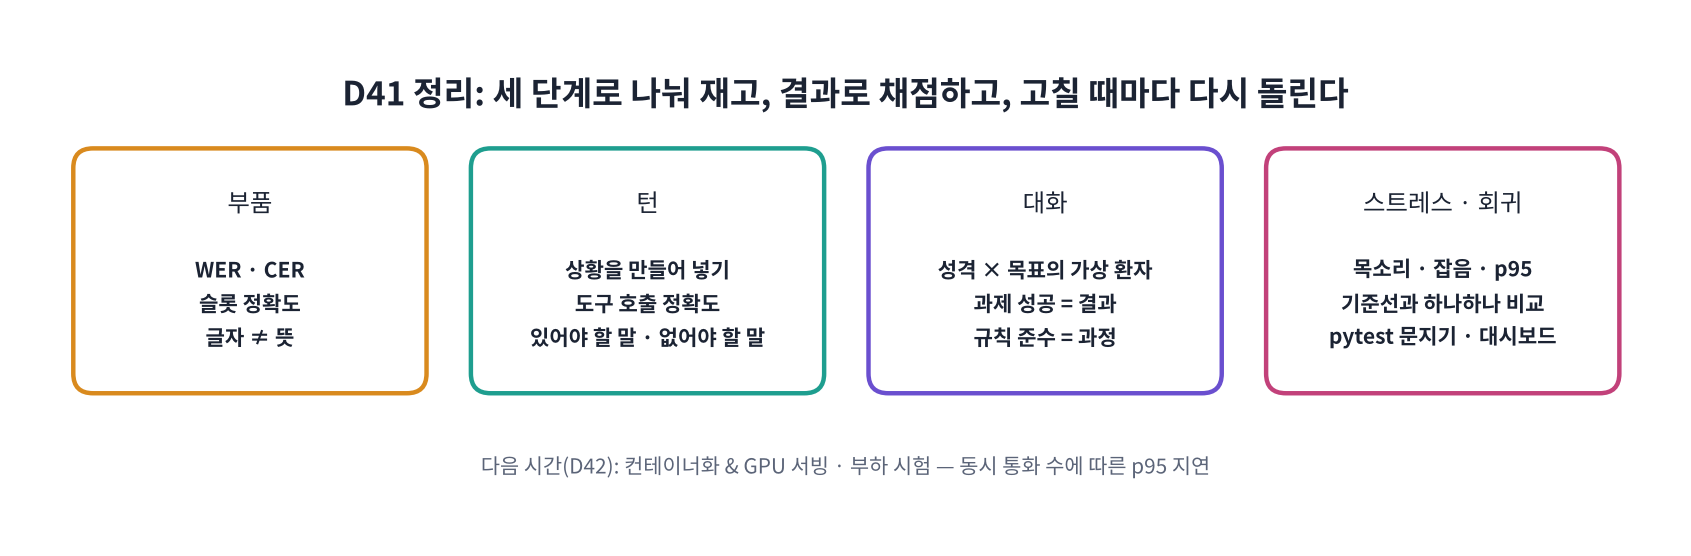

| 오늘 만든 것 | 핵심 |
|---|---|
| `wer` · `cer` · `slot_acc` | 부품: 글자가 맞았나와 **뜻이 맞았나**는 다르다 |
| `TURN_TESTS` · `run_turn` · `tool_match` | 턴: 상황을 만들어 넣고 도구 호출과 응답 조건을 검사 |
| `sim_user` · `run_dialog` | 대화: 성격 × 목표의 가상의 환자가 끝까지 통화 |
| `task_success` · `judge` · `llm_judge` | 결과로 과제 성공을, 과정으로 규칙 준수를 |
| `make_hear` · `STRESS` · `LATENCY` | 같은 시험을 목소리 · 잡음으로. 지연은 p50 · p95 |
| `regressions` · `test_hana_eval.py` · `gate` | 기준선과 하나하나 비교. 평균이 올라도 회귀가 있으면 막음 |
| `hana_eval_report.html` | 결론 → 세 단계의 숫자 → 실패한 통화 |

**오늘의 한 문장**: 좋은 평가는 **세 단계로 나눠 재고**, **결과로 채점하고**, **고칠 때마다 다시 돌려** 되던 것이 깨지지 않았는지 확인합니다.

**다음 시간 (D42) 컨테이너화 & GPU 서빙 · 부하 시험**: 오늘의 평가 하네스를 그대로 들고, 동시에 여러 통화가 들어올 때 p95 지연이 어떻게 변하는지 잽니다.